**Proyecto 1: Análisis de señales ECG y detección de arritmias**

**Integrantes:** Paula García · Valentina Morales


**Fecha de entrega:**

---

 **1.1 Diagramas de flujo**

Artículo 1. Gadaleta et al. (2023), *npj Digital Medicine*
Predicción de fibrilación auricular a 2 semanas a partir de ECG de una derivación sin arritmias.

![Diagrama artículo 1](diagrama_articulo1.png)

Artículo 2. Zheng et al. (2020), *Scientific Reports*
Clasificación multietapa de arritmias (base Chapman).

![Diagrama artículo 2](diagrama_articulo2.png)

Artículo 3. Liu et al. (2024), *Heliyon*
Clasificación de arritmias con CNN sobre ECG de una derivación, sin detección del QRS.

![Diagrama artículo 3](diagrama_articulo3.png)

---

**1.2 Explicación de las metodologías con nuestras palabras**

**Artículo 1:** La fibrilación auricular es una arritmia en la que las aurículas laten de manera descontrolada. Es difícil de detectar con métodos tradicionales porque puede aparecer y desaparecer de forma súbita e impredecible, por lo que ni un electrocardiograma de diez segundos, ni siquiera un Holter de veinticuatro horas garantizan capturar un episodio, ya que no se sabe cuándo va a ocurrir.

Frente a ese problema, el artículo propone un modelo que recibe ventanas de ECG de diez minutos y predice si la persona podría tener un episodio de fibrilación auricular en las siguientes dos semanas, aunque el ECG analizado no muestre ningún signo de la arritmia. Se usan ventanas de diez minutos por un tema de costo computacional, ya que es mucho más manejable para los modelos procesar esa cantidad de datos que la señal completa de veinticuatro horas de una sola vez.

El primer modelo se entrena con cada ventana de forma independiente y extrae ciento veintiocho parámetros propios de la morfología de la señal, que no corresponden a fórmulas definidas por médicos o estadísticos, sino a patrones que el modelo considera relevantes durante su entrenamiento. Además, para cada ventana también se calculan estadísticos ya conocidos, como la variabilidad del ritmo cardíaco y la cantidad de latidos ectópicos. En total, un día se divide en ciento cuarenta y cuatro ventanas, y por cada una se obtiene un paquete que combina los ciento veintiocho parámetros de la red con los estadísticos tradicionales. Esa secuencia completa de ventanas se le pasa al segundo modelo, que la procesa en orden temporal y decide qué tan en riesgo está la persona de sufrir fibrilación auricular.
Para evaluar el desempeño se usa el *AUC*, un índice que indica qué tan bien distingue el modelo entre una persona que va a tener fibrilación auricular y una que no, y que va de 0.5, equivalente al azar, a 1, que sería un modelo perfecto.
Usando solamente edad y sexo, el *AUC* es de 0.67; agregando la variabilidad del ritmo cardíaco sube a 0.74; y utilizando todos los datos disponibles, incluyendo los ciento veintiocho parámetros de la red neuronal y los estadísticos tradicionales, llega a 0.80.

Sin embargo, de la cohorte estudiada solo el 4.3% de las personas tuvo realmente un episodio de fibrilación auricular durante esas dos semanas. Esa baja prevalencia hace que, aunque el modelo tenga una sensibilidad del 0.80, su precisión sea naturalmente baja, de apenas 0.09, lo que significa que se generan muchos falsos positivos: de cada cien alertas de riesgo alto, solo nueve corresponden a casos reales de fibrilación auricular.

**Artículo 2:** Las arritmias cardíacas se diagnostican con un electrocardiograma, pero interpretarlo depende de que un cardiólogo lo revise, lo que toma tiempo y limita la detección a gran escala. El artículo propone un método automático que, a partir de un ECG, clasifica el ritmo que el paciente tiene en ese momento (no predice lo que pueda pasar en el futuro) en cuatro grupos: bradicardia sinusal, fibrilación o aleteo auricular, taquicardias supraventriculares y ritmo sinusal.

Se usó una base de datos de más de cuarenta mil pacientes, con ECG de doce derivaciones de diez segundos, donde los ritmos fueron diagnosticados por cardiólogos. Originalmente había once ritmos distintos, y se agruparon en cuatro según su relevancia clínica, porque algunos tenían muy pocos casos para entrenar un modelo.

Primero se limpia la señal en tres pasos: un filtro pasa-bajas que elimina el ruido de alta frecuencia, un método llamado LOESS robusto que corrige el movimiento lento de la línea base, por debajo de 0.5 Hz, y un tercer método, Non Local Means, que quita el ruido que queda. Después se detectan los picos y valles de la señal, que se clasifican en complejos QRS, picos que no son QRS y valles, y de cada uno se miden la altura, el ancho y la prominencia. También se comparan estos elementos por pares y se calculan razones respecto al tiempo entre ellos.

El problema es que cada paciente tiene un número distinto de latidos, y por lo tanto de picos y valles, pero el modelo necesita que todos los pacientes tengan la misma cantidad de datos. Por eso cada variable se resume en un histograma de cien intervalos, que cuenta cuántas veces aparece cada rango de valores. Se usa un histograma y no un promedio porque el promedio pierde la forma de la distribución: dos pacientes pueden tener el mismo valor promedio pero comportamientos muy distintos, y el histograma sí lo captura.

Con esos datos se compararon diecinueve algoritmos de clasificación combinados con cinco estrategias, ajustando sus parámetros y validando con validación cruzada de diez partes. Los mejores fueron los árboles con gradient boosting. En el boosting los árboles se construyen uno tras otro, y cada uno intenta corregir los errores del anterior, a diferencia del bagging, donde los árboles se entrenan de forma independiente y se promedian. Con este método el *F1-score* fue de 0.988 en pacientes sin otras condiciones cardíacas y de 0.97 en pacientes que sí las tenían. El F1 combina la precisión y la sensibilidad, por lo que un valor alto indica que el modelo clasifica bien sin sacrificar ninguna de las dos.

También se probó el método en la base MIT-BIH y se obtuvo un *F1-score* de 0.992, aunque ahí la tarea fue clasificar latidos individuales y no ritmos, por lo que no es una validación del mismo problema. Otra limitación es que el artículo no aclara en cuál de los cuatro grupos queda la taquicardia sinusal, que representa más del 15% de los pacientes, y que la afirmación de desempeño comparable al de cardiólogos no se midió directamente contra ellos.

**Artículo 3:** Muchos métodos de clasificación de arritmias dependen de detectar primero el complejo QRS, para medir intervalos entre latidos y calcular rasgos a partir de ahí. El problema es que esa detección falla fácilmente cuando la señal tiene ruido o movimiento, que es lo que pasa con los dispositivos portátiles. El artículo propone un método que clasifica arritmias directamente sobre la señal, sin detectar el QRS, usando una red neuronal convolucional.

Se usan señales de una sola derivación de tres bases de datos de PhysioNet, con nueve ritmos cardíacos: ritmo sinusal normal, fibrilación auricular, aleteo auricular, Wolff-Parkinson-White, bloqueo Mobitz II, bradicardia sinusal, taquicardia ventricular, fibrilación ventricular y aleteo ventricular. Como las bases venían con frecuencias de muestreo distintas, todas se llevaron a 250 Hz. Luego las señales se cortaron en segmentos de cinco y de diez segundos, y para aumentar el número de muestras se usaron ventanas superpuestas, es decir, segmentos que comparten una parte de la señal con el siguiente.

La red recibe el segmento completo y tiene cuatro capas convolucionales, con max pooling entre ellas. La primera capa detecta patrones simples de la señal, y las siguientes los van combinando en estructuras cada vez más complejas. El max pooling reduce el tamaño de lo que se procesa y conserva lo más relevante. Al final, capas totalmente conectadas y una función softmax dan la probabilidad de que el segmento corresponda a cada uno de los nueve ritmos.

Con segmentos de cinco segundos la exactitud fue de 96.51%, y con diez segundos de 98.1%. Además, el modelo de cinco segundos se probó con una base distinta, CUDB, que no se usó para entrenar y en la que se emplearon los ritmos completos sin solapamiento, y ahí la exactitud bajó a 91.6%. Una de las confusiones más frecuentes fue clasificar fibrilación auricular como aleteo auricular.

Hay varias limitaciones. Con ventanas superpuestas puede haber fuga de datos: si una ventana queda en entrenamiento y otra, que comparte parte de la misma señal, queda en validación, el modelo estaría evaluándose con algo que ya vio casi igual, lo que inflaría la exactitud interna. El artículo no aclara cómo se dividieron los datos, así que esto es una posibilidad y no algo confirmado. Eso encaja con que la exactitud baje en la prueba externa.

---

**2.1 Carga y revisión general de los datos**

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RUTA_DIAGNOSTICS = Path("Diagnostics.xlsx")  
RUTA_SENALES = Path("ECGDataDenoised")     

df = pd.read_excel(RUTA_DIAGNOSTICS)

print(df.shape)
display(df.head())
display(df.dtypes)

# faltantes y duplicados
print(df.isna().sum().sum(), "faltantes;", df.duplicated().sum(), "filas duplicadas;",
      df["FileName"].duplicated().sum(), "FileName repetidos")

# resumen numérico y categórico
display(df.describe().T)
for c in ["Rhythm", "Gender"]:
    display(df[c].value_counts())
print("Beat:", df["Beat"].nunique(), "combinaciones;", (df["Beat"] == "NONE").mean().round(3), "es NONE")

# chequeos de rango
print("menores de 18:", (df.PatientAge < 18).sum())
print("QRS < 40 ms:", (df.QRSDuration < 40).sum())
print("AtrialRate == 0:", (df.AtrialRate == 0).sum())

(10646, 16)


,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


FileName           object
Rhythm             object
Beat               object
PatientAge          int64
Gender             object
VentricularRate     int64
AtrialRate          int64
QRSDuration         int64
QTInterval          int64
QTCorrected         int64
RAxis               int64
TAxis               int64
QRSCount            int64
QOnset              int64
QOffset             int64
TOffset             int64
dtype: object

0 faltantes; 0 filas duplicadas; 0 FileName repetidos


,count,mean,std,min,25%,50%,75%,max
PatientAge,10646.0,59.186831,18.030019,4.0,49.0,62.0,72.0,98.0
VentricularRate,10646.0,84.136107,34.455349,34.0,57.0,73.0,104.0,263.0
AtrialRate,10646.0,92.577870,60.093940,0.0,57.0,72.0,106.0,535.0
QRSDuration,10646.0,90.989292,17.479540,18.0,80.0,88.0,98.0,256.0
QTInterval,10646.0,384.150855,59.226289,114.0,344.0,390.0,426.0,736.0
QTCorrected,10646.0,434.154048,39.354182,219.0,408.0,430.0,456.0,760.0
RAxis,10646.0,39.620609,41.212648,-89.0,14.0,46.0,68.0,270.0
TAxis,10646.0,44.637704,57.478092,-89.0,19.0,42.0,62.0,270.0
QRSCount,10646.0,13.839470,5.676339,5.0,9.0,12.0,17.0,40.0
QOnset,10646.0,219.260567,6.410413,159.0,216.0,219.0,224.0,240.0


Rhythm
SB       3889
SR       1826
AFIB     1780
ST       1568
SVT       587
AF        445
SA        399
AT        121
AVNRT      16
AVRT        8
SAAWR       7
Name: count, dtype: int64

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64

Beat: 742 combinaciones; 0.509 es NONE
menores de 18: 265
QRS < 40 ms: 1
AtrialRate == 0: 12


La base `Diagnostics.xlsx` contiene 10.646 registros, uno por paciente, y 16 variables: el nombre del archivo de la señal (`FileName`), el ritmo cardíaco (`Rhythm`), otras condiciones del ECG (`Beat`), la edad, el sexo y 11 mediciones del electrocardiograma, entre ellas las frecuencias ventricular y auricular, la duración del QRS, los intervalos QT y los ejes eléctricos. No hay valores faltantes ni registros duplicados, y cada `FileName` es único, lo que permite emparejar cada fila con su señal.

Hay 11 ritmos: SB (bradicardia sinusal), SR (ritmo sinusal), ST (taquicardia sinusal), AFIB (fibrilación auricular), AF (aleteo auricular), SA (irregularidad sinusal), SVT (taquicardia supraventricular), AT (taquicardia auricular), AVNRT, AVRT y SAAWR (marcapasos auricular errante).

La edad de los pacientes tiene una media de 59 años (desviación estándar de 18), una mediana de 62 y va de 4 a 98 años. El 56% son hombres (5.956) y el 44% mujeres (4.690). La frecuencia ventricular media es de 84 latidos por minuto y la duración media del QRS es de 91 ms. El ritmo más frecuente es la bradicardia sinusal, y tres ritmos (SB, SR y AFIB) concentran cerca del 70% de los registros, mientras que AVNRT, AVRT y SAAWR tienen menos de 20 registros cada uno.

Como observaciones sobre la calidad de los datos: hay 265 pacientes menores de 18 años, un registro con una duración del QRS de 18 ms, que es fisiológicamente imposible y probablemente un error de medición, y la columna `Beat` contiene 742 combinaciones de condiciones adicionales, de las cuales el 51% corresponde a `NONE`. Estos aspectos se tendrán en cuenta en los análisis siguientes.

---

**2.2 ¿Qué tipo de arritmias son más prevalentes?**

,n,%
Rhythm,,
SB,3889,36.53
SR,1826,17.15
AFIB,1780,16.72
ST,1568,14.73
SVT,587,5.51
AF,445,4.18
SA,399,3.75
AT,121,1.14
AVNRT,16,0.15


,n,% de arritmias
Rhythm,,
SB,3889,44.09
AFIB,1780,20.18
ST,1568,17.78
SVT,587,6.66
AF,445,5.05
SA,399,4.52
AT,121,1.37
AVNRT,16,0.18
AVRT,8,0.09


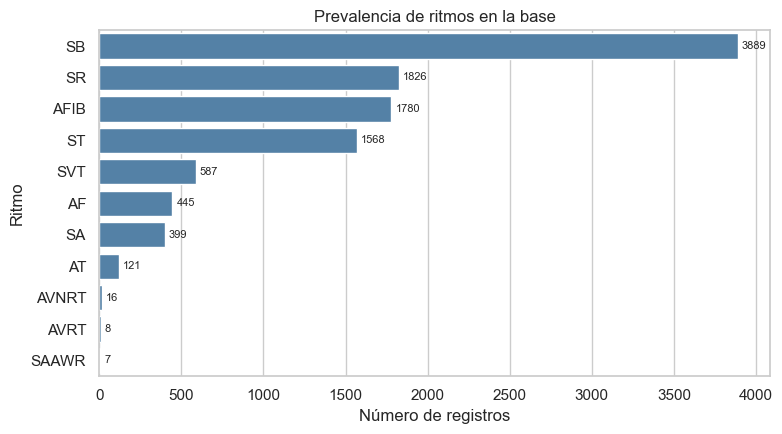

In [66]:
# Prevalencia de los 11 ritmos
prev = df["Rhythm"].value_counts().to_frame("n")
prev["%"] = (100 * prev["n"] / len(df)).round(2)
display(prev)

# Sin SR (ritmo normal): solo arritmias
arr = df[df["Rhythm"] != "SR"]
prev_arr = arr["Rhythm"].value_counts().to_frame("n")
prev_arr["% de arritmias"] = (100 * prev_arr["n"] / len(arr)).round(2)
display(prev_arr)

# Gráfico
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, y="Rhythm", order=prev.index, color="steelblue", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2),
                va="center", ha="left", fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_xlabel("Número de registros")
ax.set_ylabel("Ritmo")
ax.set_title("Prevalencia de ritmos en la base")
plt.tight_layout()
plt.show()

El ritmo más frecuente en la base es la bradicardia sinusal (SB), con 3.889 registros (36,5% del total). Le siguen el ritmo sinusal normal (SR, 17,2%), la fibrilación auricular (AFIB, 16,7%) y la taquicardia sinusal (ST, 14,7%). Estos cuatro ritmos concentran el 85% de la base. Los demás son menos frecuentes: la taquicardia supraventricular (SVT) representa el 5,5%, el aleteo auricular (AF) el 4,2% y la irregularidad sinusal (SA) el 3,8%, mientras que AT, AVNRT, AVRT y SAAWR están por debajo del 1,2%.

Como SR es el ritmo normal y no una arritmia, al excluirlo (8.820 registros) las arritmias más prevalentes son la bradicardia sinusal (44,1%), la fibrilación auricular (20,2%) y la taquicardia sinusal (17,8%).

---

**2.3 ¿Hay arritmias más prevalentes para un género específico?**


Gender,FEMALE,MALE,total,% hombres,% mujeres
Rhythm,,,,,
SB,1408,2481,3889,63.8,36.2
SR,1024,802,1826,43.9,56.1
AFIB,739,1041,1780,58.5,41.5
ST,769,799,1568,51.0,49.0
SVT,308,279,587,47.5,52.5
AF,188,257,445,57.8,42.2
SA,176,223,399,55.9,44.1
AT,57,64,121,52.9,47.1
AVNRT,12,4,16,25.0,75.0


% de hombres en toda la base: 55.9%


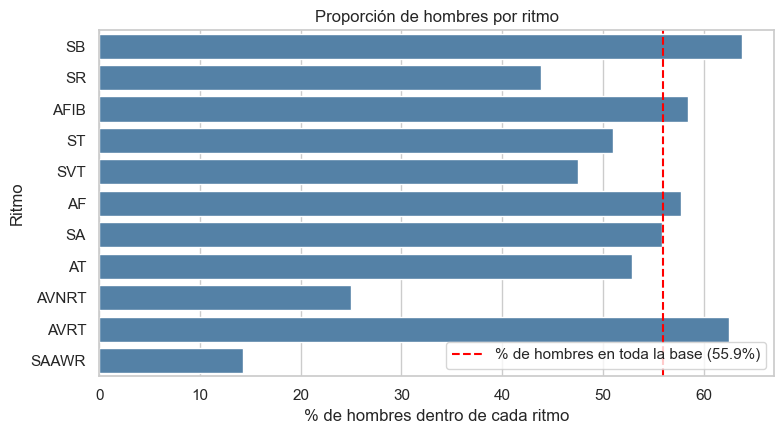

In [67]:
# Tabla ritmo x sexo
orden = df["Rhythm"].value_counts().index
ct = pd.crosstab(df["Rhythm"], df["Gender"]).loc[orden, ["FEMALE", "MALE"]]
ct["total"] = ct.sum(axis=1)
ct["% hombres"] = (100 * ct["MALE"] / ct["total"]).round(1)
ct["% mujeres"] = (100 * ct["FEMALE"] / ct["total"]).round(1)
display(ct)

base_h = 100 * (df["Gender"] == "MALE").mean()
print(f"% de hombres en toda la base: {base_h:.1f}%")

# Gráfico: % de hombres por ritmo
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=ct.reset_index(), y="Rhythm", x="% hombres", order=orden, color="steelblue", ax=ax)
ax.axvline(base_h, color="red", linestyle="--", label=f"% de hombres en toda la base ({base_h:.1f}%)")
ax.set_xlabel("% de hombres dentro de cada ritmo")
ax.set_ylabel("Ritmo")
ax.set_title("Proporción de hombres por ritmo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

El 55,9% de los registros de la base de datos corresponde a hombres, por lo que se compara la proporción de hombres de cada ritmo contra ese valor. 

La bradicardia sinusal es más frecuente en hombres (63,8%). En mujeres son más frecuentes el ritmo sinusal normal (56,1% de mujeres), la taquicardia supraventricular (52,5%) y, en menor medida, la taquicardia sinusal (49,0%). La fibrilación auricular (58,5% de hombres), el aleteo auricular y la irregularidad sinusal se mantienen cerca del valor de la base. En AVNRT, AVRT y SAAWR hay muy pocos registros (16, 8 y 7) para concluir algo.

---

**2.4 ¿Hay arritmias más prevalentes para una edad?**


,count,mean,std,min,25%,50%,75%,max
Rhythm,,,,,,,,
SA,399.0,34.7,23.0,4.0,14.5,29.0,52.5,93.0
SAAWR,7.0,51.1,31.8,15.0,22.5,49.0,81.0,87.0
SR,1826.0,54.4,16.3,4.0,44.0,55.0,66.0,95.0
SVT,587.0,55.6,18.5,4.0,42.0,56.0,69.0,96.0
ST,1568.0,54.6,21.1,4.0,40.0,57.0,70.0,96.0
AVNRT,16.0,57.9,17.3,27.0,51.0,59.0,66.0,84.0
SB,3889.0,58.3,14.0,10.0,50.0,60.0,68.0,98.0
AVRT,8.0,57.5,16.8,25.0,47.8,62.5,67.0,77.0
AT,121.0,65.7,19.3,8.0,60.0,71.0,77.0,94.0


,n
GrupoEdad,
<18,265
18-39,1247
40-59,3298
60-79,4481
≥80,1355


GrupoEdad,<18,18-39,40-59,60-79,≥80
Rhythm,,,,,
SB,6.8,29.3,46.3,39.5,15.4
SR,8.7,26.4,22.3,14.3,7.4
AFIB,0.0,0.6,5.8,21.6,45.0
ST,32.1,23.3,13.9,12.0,14.5
SVT,4.2,8.5,6.7,4.0,5.3
AF,0.0,0.6,2.1,5.4,9.4
SA,45.7,10.3,2.2,1.5,1.0
AT,2.3,0.6,0.5,1.6,1.7
AVNRT,0.0,0.2,0.2,0.1,0.2


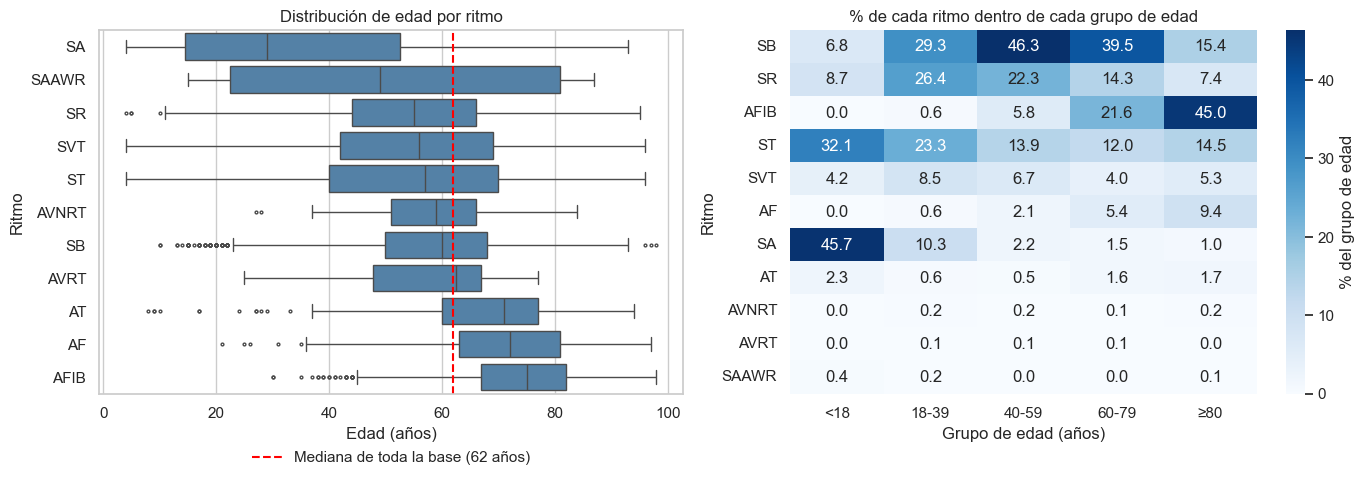

In [68]:
# Edad por ritmo (ordenado por mediana de edad)
orden = df["Rhythm"].value_counts().index
edad_ritmo = (df.groupby("Rhythm")["PatientAge"]
                .describe()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
                .sort_values("50%").round(1))
display(edad_ritmo)

# Grupos de edad
bins = [0, 18, 40, 60, 80, 120]
grupos = ["<18", "18-39", "40-59", "60-79", "≥80"]
df["GrupoEdad"] = pd.cut(df["PatientAge"], bins=bins, labels=grupos, right=False)
display(df["GrupoEdad"].value_counts().loc[grupos].to_frame("n"))

# % de cada ritmo dentro de cada grupo de edad (cada columna suma 100%)
ct_edad = pd.crosstab(df["Rhythm"], df["GrupoEdad"], normalize="columns").loc[orden] * 100
display(ct_edad.round(1))

# Gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, y="Rhythm", x="PatientAge", order=edad_ritmo.index,
            color="steelblue", fliersize=2, ax=axes[0])
axes[0].axvline(df["PatientAge"].median(), color="red", linestyle="--",
                label=f"Mediana de toda la base ({df['PatientAge'].median():.0f} años)")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Ritmo")
axes[0].set_title("Distribución de edad por ritmo")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)

sns.heatmap(ct_edad, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% del grupo de edad"}, ax=axes[1])
axes[1].set_xlabel("Grupo de edad (años)")
axes[1].set_ylabel("Ritmo")
axes[1].set_title("% de cada ritmo dentro de cada grupo de edad")
plt.tight_layout()
plt.show()

Se comparó la edad de los pacientes dentro de cada ritmo (mediana y rango intercuartílico) y se dividió la base en cinco grupos de edad (<18, 18-39, 40-59, 60-79 y ≥80 años), calculando qué porcentaje de cada grupo corresponde a cada ritmo. Esto permite comparar grupos de distinto tamaño (por ejemplo, el de 60-79 tiene 4.481 registros y el de <18 solo 265).

Sí hay ritmos claramente asociados a la edad. La fibrilación auricular (AFIB) es el ritmo de pacientes más mayores, con una mediana de 75 años (rango intercuartílico de 67 a 82), seguida del aleteo auricular (AF, 72 años) y la taquicardia auricular (AT, 71 años), todos por encima de la mediana de la base, que es de 62 años. En el otro extremo está la irregularidad sinusal (SA), con una mediana de 29 años y la mitad de sus pacientes entre 14 y 52 años. El ritmo sinusal normal (SR, 55 años), la taquicardia supraventricular (SVT, 56 años), la taquicardia sinusal (ST, 57 años) y la bradicardia sinusal (SB, 60 años) quedan por debajo de la mediana general.

Por grupos de edad, el ritmo más frecuente cambia según la edad:
- En los menores de 18 años predominan la irregularidad sinusal (45,7%) y la taquicardia sinusal (32,1%), y no hay ningún caso de AFIB ni de AF.
- Entre 18 y 39 años los ritmos más comunes son la bradicardia sinusal (29,3%), el ritmo sinusal normal (26,4%) y la taquicardia sinusal (23,3%).
- Entre 40 y 59 años la bradicardia sinusal alcanza su máximo (46,3%), y es también el ritmo más frecuente entre 60 y 79 años (39,5%), seguida de la fibrilación auricular (21,6%).
- En los mayores de 80 años la fibrilación auricular pasa a ser el ritmo más frecuente (45,0%), y la bradicardia sinusal baja a 15,4%.

La tendencia más marcada es la de la fibrilación auricular, que pasa de 0% en menores de 18 años a 0,6%, 5,8%, 21,6% y 45,0% en los grupos siguientes. El aleteo auricular sigue el mismo patrón, aunque con valores más bajos (de 0% a 9,4%). La irregularidad sinusal hace lo contrario: baja de 45,7% en menores de 18 años a 10,3% entre 18 y 39 años, y queda por debajo del 2,5% a partir de los 40. A partir de los 18 años, el ritmo sinusal normal también disminuye con la edad, de 26,4% entre 18 y 39 años a 7,4% en los mayores de 80.

En AVNRT, AVRT y SAAWR, como en el punto 2.3, hay muy pocos registros (16, 8 y 7) para concluir algo sobre su relación con la edad.

En los menores de 18 años la frecuencia cardíaca normal es más alta que en adultos, por lo que parte de la "taquicardia sinusal" de ese grupo (frecuencia mediana de 120 latidos por minuto) podría corresponder a un ritmo normal para su edad. No se conoce qué criterios se usaron para etiquetar a los menores, por lo que este grupo se tratará con cautela al elegir el rango de edades en el punto siguiente.

---

**2.5 Los algoritmos de aprendizaje se basan en usar la mayor cantidad
de datos posibles que sean comparables, ¿Qué rango de edades y
arritmias de la base de datos entregada considera que debe usar
para entrenar algoritmos de aprendizaje?**


A partir del análisis anterior de `Diagnostics.xlsx`, se eligen los cuatro ritmos con más registros: bradicardia sinusal (SB), ritmo sinusal (SR), fibrilación auricular (AFIB) y taquicardia sinusal (ST), que juntos suman 9.063 registros (85% de la base). Se incluye SR aunque corresponde al ritmo normal, porque un algoritmo que detecta arritmias necesita ejemplos de un ECG normal para aprender a diferenciarlo de uno anormal. Los demás ritmos se dejan fuera por tener menos registros, y AVNRT, AVRT y SAAWR (16, 8 y 7) por ser muy pocos para cualquier análisis.

En cuanto a la edad, se elige el rango de 40 a 79 años, que corresponde a los dos grupos con más registros (40-59 y 60-79, con 3.298 y 4.481). Además, la fibrilación auricular casi no aparece antes de los 40 años (solo 8 registros), por lo que incluir adultos jóvenes aumentaría la diferencia de edad entre AFIB y los demás ritmos. En este rango quedan 3.298 registros de SB, 1.374 de SR, 1.162 de AFIB y 997 de ST, para un total de 6.831 (64% de la base).

La fibrilación auricular es el ritmo más frecuente en los mayores de 80 años (45% de ese grupo), así que al excluirlos se pierden 610 registros de AFIB, cerca de un tercio de esa clase. Aun así, se decide no incluirlos para evitar que el modelo asocie la edad con la arritmia en vez de aprender las características de la señal. Esto reduce la diferencia de edad entre clases, pero no la elimina: la mediana de AFIB en este rango es de 69 años, frente a 58 (SR), 60 (SB) y 61 (ST). Además, hay desbalance entre clases (SB tiene 3,3 veces más registros que ST) y diferencias de sexo entre ritmos, que habrá que tener en cuenta al analizar los resultados.

---

**2.6 ¿Hay coincidencia entre lo encontrado en literatura y lo encontrado
en la base de datos?**

**Comparación con los artículos**

En el artículo [1], la edad y el sexo por sí solos permiten predecir el riesgo de fibrilación auricular con un AUC de 0,67, lo que indica que ambas variables aportan información sobre ese riesgo, aunque de forma modesta (con muchas más variables el modelo llega a 0,80). Esto es consistente con la base, donde AFIB es el ritmo con los pacientes más mayores (mediana de 75 años). En cuanto al sexo, AFIB tiene 58,5% de hombres, una proporción cercana a la de toda la base (55,9%), por lo que no se distingue claramente de ella; la literatura reporta una relación de 1,2 hombres por mujer [4].

El artículo [2] trabaja con una base de los mismos hospitales (Shaoxing y Ningbo), pero más grande (40.258 pacientes). Sus características son parecidas a las de nuestra base: el 56% de sus pacientes son hombres, igual que en la nuestra (55,9%); los grupos de edad más frecuentes son 51-60, 61-70 y 71-80 años, lo que coincide con nuestra mediana de 62 años y con los grupos de 40-59 y 60-79 como los más numerosos; y cerca del 20% de sus registros son ritmo sinusal normal, frente al 17,2% de SR en nuestra base. Además, este artículo agrupa los ritmos en SB, AFIB, taquicardias supraventriculares (GSVT) y SR, de los cuales tres coinciden con los que elegimos en el apartado anterior. La diferencia es que nosotros incluimos la taquicardia sinusal (ST) en lugar de GSVT, y que el artículo no aclara en qué grupo queda ST.

**Comparación con la literatura clínica**

- **Fibrilación auricular:** la literatura reporta que su prevalencia aumenta con la edad, de 0,12-0,16% en menores de 49 años a 10-17% en mayores de 80, y que es algo más frecuente en hombres, con una relación de 1,2 hombres por cada mujer [4]. En la base se observa la misma tendencia con la edad: AFIB pasa de 0% en menores de 18 años a 45% en mayores de 80.
- **Taquicardias supraventriculares:** la AVNRT, que es la más común en adultos, afecta con mayor frecuencia a mujeres jóvenes y sanas [5]. En la base, SVT es uno de los pocos ritmos con más mujeres que hombres (52,5% de mujeres), y en AVNRT 12 de los 16 registros son de mujeres, aunque son muy pocos datos para concluir.
- **Irregularidad sinusal:** se presenta sobre todo en niños y adultos jóvenes sanos, y un estudio en adultos sanos encontró que la arritmia sinusal respiratoria en personas de 50 a 71 años tiene menos del 20% de la prevalencia que en menores de 31 años [6]. Esto coincide con la base, donde SA tiene una mediana de 29 años y es el ritmo más frecuente en menores de 18 años (45,7%).

**Diferencias**

La principal diferencia es la magnitud de las prevalencias. En la población general la fibrilación auricular es la arritmia sostenida más común [4], mientras que en nuestra base el ritmo más frecuente es la bradicardia sinusal (36,5%). Además, el 45% de los mayores de 80 años de la base tiene AFIB, mucho más que el 10-17% reportado en la población general. Esto se debe a que la base no es una muestra de la población general, sino de pacientes a los que se les tomó un ECG en un hospital, donde es más probable encontrar arritmias. Por eso los porcentajes de la base sirven para comparar tendencias (qué ritmos aumentan con la edad o predominan en un sexo), pero no para estimar cuántas personas tienen cada arritmia en la población.

---


**2.7 ¿Qué otros análisis propone desde la base de datos?**

A partir de la base de datos se proponen los siguientes análisis:

**1. Pruebas estadísticas.** En los puntos anteriores la relación de los ritmos con la edad se describió con porcentajes y gráficos. Se propone confirmarla con pruebas estadísticas. Como hay miles de registros por ritmo, las pruebas de normalidad rechazan casi siempre, por lo que se usaría una prueba no paramétrica (Kruskal-Wallis y comparaciones por pares con Mann-Whitney, corrigiendo por comparaciones múltiples) y se reportaría también el tamaño del efecto, porque con muestras tan grandes casi cualquier diferencia resulta significativa. Por ejemplo, en el subconjunto elegido, entre AFIB y SR la diferencia de mediana es grande (69 frente a 58 años), mientras que entre SB y SR (60 frente a 58 años) es estadísticamente significativa pero muy pequeña en la práctica.

**2. Comparación de los parámetros del ECG entre ritmos.** La base incluye mediciones como la duración del QRS, el QT corregido y las frecuencias ventricular y auricular, que se podrían comparar entre los ritmos del subconjunto elegido en el punto 2.5 mediante diagramas de caja. La frecuencia ventricular separa SB, SR y ST casi por definición (menos de 60, entre 60 y 100 y más de 100 lpm), por lo que sería más informativo comparar la duración del QRS y el QT corregido. En AFIB se observa además una frecuencia ventricular mucho más dispersa (desviación estándar de 27 lpm frente a 4 a 11 en los otros ritmos). La frecuencia auricular, en cambio, es poco confiable en fibrilación auricular, por la actividad desorganizada de las aurículas, y no se interpretaría directamente.

**3. Condiciones adicionales.** Además del ritmo, muchos pacientes tienen otras condiciones registradas, como bloqueos de rama o alteraciones del segmento ST y de la onda T. Cerca de la mitad de los registros tiene alguna, y la proporción varía mucho entre los ritmos del subconjunto (AFIB 72,5%, ST 62,0%, SB 43,4% y SR 26,0%). Esto es importante porque esas condiciones también modifican la forma del ECG, y un modelo podría aprender a reconocerlas en lugar del ritmo. El artículo [2] reportó un desempeño menor en pacientes con otras condiciones (F1 de 0,97 frente a 0,988), por lo que se propone comparar los resultados de los puntos siguientes con y sin estos pacientes.

---

**Con base en el análisis descriptivo del punto anterior, seleccionar un subconjunto de datos para trabajar en los siguientes análisis:**



---

In [69]:
# Subconjunto de trabajo: SB, SR, AFIB y ST entre 40 y 79 años
ritmos_sel = ["SB", "SR", "AFIB", "ST"]
df_sel = df[df["Rhythm"].isin(ritmos_sel) & df["PatientAge"].between(40, 79)].copy()

print("Registros en el subconjunto:", len(df_sel), f"({100 * len(df_sel) / len(df):.1f}% de la base)")
display(df_sel["Rhythm"].value_counts().to_frame("n"))

# Resumen del subconjunto por ritmo
resumen = (df_sel.groupby("Rhythm")
           .agg(n=("FileName", "count"),
                edad_mediana=("PatientAge", "median"),
                pct_hombres=("Gender", lambda g: 100 * (g == "MALE").mean()),
                fc_mediana=("VentricularRate", "median"))
           .loc[ritmos_sel].round(1))
display(resumen)

# Guardar el subconjunto y marcar los registros en la tabla completa
df_sel.to_csv("subconjunto_2_8.csv", index=False)
df["en_subconjunto"] = df["FileName"].isin(df_sel["FileName"])
print(df["en_subconjunto"].sum(), "registros marcados")   # debe dar 6831

Registros en el subconjunto: 6831 (64.2% de la base)


,n
Rhythm,
SB,3298
SR,1374
AFIB,1162
ST,997


,n,edad_mediana,pct_hombres,fc_mediana
Rhythm,,,,
SB,3298,60.0,63.6,56.0
SR,1374,58.0,43.6,74.0
AFIB,1162,69.0,59.3,91.0
ST,997,61.0,50.9,108.0


6831 registros marcados


**3. Programar las fórmulas 1 al 4 que se encuentran en el artículo. Consultar que significado y utilidad del biespectro**


In [70]:
# Parámetros
FS = 500          # Hz (frecuencia de muestreo de la base)
L = 500           # muestras por segmento (1 s) -> N = 10 segmentos en 5000 muestras
FMAX = 20         # Hz (rango de bicoherencia, como en el paper)
N_DETREND = 20    # grado del polinomio (el paper reporta que δ(n) satura para n > 20)

# Fórmula 1: desviación entre la señal original y la señal sin tendencia
def quitar_tendencia(x, n=N_DETREND):
    """Ajusta un polinomio de grado n y lo resta (detrending)."""
    tt = np.arange(len(x))
    tendencia = np.polynomial.Polynomial.fit(tt, x, n)(tt)
    return x - tendencia

def desviacion(x0, xn):
    """δ(n) = (1/k) Σ (x0(i) - xn(i))², con k = longitud de la señal."""
    k = len(x0)
    return np.sum((x0 - xn) ** 2) / k

# Fórmula 2: compresión al rango [0, 1]
def comprimir(x):
    """s(t_k) = (x(t_k) - x_min) / (x_max - x_min)"""
    return (x - x.min()) / (x.max() - x.min())

# Auxiliares
def fft_segmentos(x, L):
    """Divide la señal en N segmentos de L muestras (sin solapamiento) y calcula la FFT de cada uno."""
    N = len(x) // L
    if N < 2:
        raise ValueError(f"Con L = {L} solo se forman {N} segmentos; se necesitan al menos 2.")
    return np.fft.fft(x[:N * L].reshape(N, L), axis=1), N

def umbral_bicoherencia(N):
    """Umbral del paper: sqrt(9.2 / (2N)), con N = número de segmentos."""
    return np.sqrt(9.2 / (2 * N))

def mascara_triangular(f, fmax=FMAX):
    """Región válida del paper: f2 > 0, f1 >= f2, f1 + f2 <= fmax."""
    F1, F2 = np.meshgrid(f, f, indexing="ij")
    return (F1 >= F2) & (F1 + F2 <= fmax)

def productos_triples(x, fs=FS, L=L, fmax=FMAX):
    """X_j(f1) · X_j(f2) · X_j*(f1+f2) para cada segmento j y cada par (f1, f2)."""
    X, N = fft_segmentos(x, L)
    k = np.arange(1, int(fmax * L / fs) + 1)          # sin f = 0
    K1, K2 = np.meshgrid(k, k, indexing="ij")
    prod = X[:, K1] * X[:, K2] * np.conj(X[:, K1 + K2])
    return k * fs / L, prod, N

# Fórmula 3: biespectro
def biespectro(x, fs=FS, L=L, fmax=FMAX):
    """b(f1, f2) = Σ_j X_j(f1) X_j(f2) X_j*(f1+f2). Devuelve (f, b, N)."""
    f, prod, N = productos_triples(x, fs, L, fmax)
    return f, prod.sum(axis=0), N

# Fórmula 4: bicoherencia
def bicoherencia(x, fs=FS, L=L, fmax=FMAX):
    """B(f1, f2) = |Σ_j X_j(f1) X_j(f2) X_j*(f1+f2)| / Σ_j |X_j(f1) X_j(f2) X_j*(f1+f2)|. Devuelve (f, B, N)."""
    f, prod, N = productos_triples(x, fs, L, fmax)
    if umbral_bicoherencia(N) >= 1:
        raise ValueError(f"N = {N} segmentos da un umbral >= 1; usa una ventana más corta.")
    num = np.abs(prod.sum(axis=0))
    den = np.abs(prod).sum(axis=0)
    B = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
    return f, B, N

Validación con señal sintética:

In [71]:
rng = np.random.default_rng(0)
t = np.arange(L) / FS

def senal_prueba(acoplada, nseg=10):
    seg = []
    for _ in range(nseg):
        p1, p2, p3 = rng.uniform(0, 2 * np.pi, 3)
        fase3 = p1 + p2 if acoplada else p3
        seg.append(np.cos(2*np.pi*5*t + p1) + np.cos(2*np.pi*3*t + p2)
                   + np.cos(2*np.pi*8*t + fase3) + 0.1 * rng.standard_normal(L))
    return np.concatenate(seg)

for acoplada in (True, False):
    f, B, N = bicoherencia(senal_prueba(acoplada))
    i, j = np.argmin(abs(f - 5)), np.argmin(abs(f - 3))
    print("acoplada" if acoplada else "no acoplada", "-> B(5,3) =", round(B[i, j], 3), "| N =", N)

print("celdas del triángulo:", int(mascara_triangular(f).sum()),
      "| umbral con N = 10:", round(umbral_bicoherencia(10), 3))

acoplada -> B(5,3) = 1.0 | N = 10
no acoplada -> B(5,3) = 0.389 | N = 10
celdas del triángulo: 100 | umbral con N = 10: 0.678


**Fórmula 1: desviación por la eliminación de la tendencia**

$$\delta(n) = \frac{1}{k}\sum_{i=1}^{k}\left(x^{(0)}(i) - x^{(n)}(i)\right)^2$$

Las señales de ECG pueden tener una tendencia global causada por movimientos del paciente o por fluctuaciones de voltaje del equipo, por lo que se debe quitar antes de procesarlas. Para eso se ajusta un polinomio de grado *n* y se resta de la señal original $x^{(0)}$, y la fórmula mide la desviación promedio entre la señal original y la señal sin tendencia $x^{(n)}$, donde *k* es la longitud de las señales. El artículo encuentra que δ(n) se satura para *n* mayor que 20, y por eso usa n = 20 en todos los casos.

**Fórmula 2: compresión**

$$s(t_k) = \frac{x(t_k) - x_{min}}{x_{max} - x_{min}}$$

Lleva todos los valores de la señal al rango entre 0 y 1 sin alterar su forma, para comparar señales de distintos pacientes de manera uniforme. Aquí $x_{max}$ y $x_{min}$ son el máximo y el mínimo de la señal. El artículo no aclara si esta compresión se aplica antes o después de quitar la tendencia; se supone que se aplica sobre la señal sin tendencia. (El artículo escribe c(t_k) en el numerador, que parece un error tipográfico; se usó x(t_k).)

**Fórmula 3: biespectro**

$$b(f_1, f_2) = \sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)$$

La señal se divide en *N* segmentos y se calcula la transformada de Fourier $X_j$ de cada uno con el algoritmo FFT. Para cada par de frecuencias (f1, f2) se multiplica la componente en f1, la componente en f2 y el conjugado de la componente en f1 + f2, y se suma sobre los *N* segmentos.

**Fórmula 4: bicoherencia**

$$B(f_1, f_2) = \frac{\left|\sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)\right|}{\sum_{j=1}^{N}\left|X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)\right|}$$

Es el biespectro normalizado para que su valor quede entre 0 y 1. Se puede calcular a partir de una sola señal, y se calcula en el rango de 0 a 20 Hz, que es donde el artículo encuentra la mayor parte de la potencia, en la región f₂ > 0, f₁ ≥ f₂ y f₁ + f₂ ≤ 20 Hz.

**Longitud de los segmentos.** El artículo usa segmentos de 8192 muestras en registros de 60 s a 1000 Hz. Los de esta base tienen 5000 muestras (10 s a 500 Hz), con las que no se puede formar ni un segmento de ese tamaño, y además la señal es mucho más corta, por lo que se forman menos segmentos. Por eso la longitud *L* es un parámetro de las funciones, y se usa L = 500 (1 s), que da N = 10 segmentos, una resolución en frecuencia de 1 Hz y un umbral de significancia de $\sqrt{9{,}2/(2N)} = 0{,}68$. Con L = 1000 se obtendrían solo 5 segmentos y un umbral de 0,96, casi inalcanzable.

**Validación de las funciones**

Para comprobar que las funciones calculan lo esperado se usó una señal sintética formada por tres senos de 3, 5 y 8 Hz. Cuando la fase del seno de 8 Hz está acoplada a la de los otros dos (fase = fase₅ + fase₃), la bicoherencia en (5, 3) es 1,0. Cuando su fase es independiente, el valor baja a 0,39, que es el nivel esperado por azar con N = 10 segmentos.

--- 

**3.2 ¿Qué es un biespectro y cuál es su utilidad?**

El espectro de potencia indica cuánta potencia tiene una señal en cada frecuencia, pero no dice nada sobre la relación de fase entre ellas. El biespectro, que es la transformada de Fourier de la correlación de tercer orden, sí lo hace: mide el acoplamiento cuadrático de fase entre las frecuencias f1, f2 y f1 + f2, y permite detectar procesos no lineales y no gaussianos [7]. Su versión normalizada entre 0 y 1 es la bicoherencia, que indica el grado de acoplamiento de fase para cada par de frecuencias.

En el ECG sirve para distinguir un ritmo normal de uno patológico. Según el artículo [7], en ECG normales la frecuencia del pulso (cerca de 1 Hz) tiene la máxima potencia y un acoplamiento de fase fuerte con muchas frecuencias más altas, mientras que en los casos patológicos esa potencia se reduce y se distribuye hacia frecuencias más altas, y la pérdida o disminución del acoplamiento con la frecuencia del pulso es un indicador de condiciones anormales. Además, características calculadas a partir del biespectro han permitido separar complejos QRS normales de varias clases de arritmias en la base MIT-BIH [8].

---

**4. Para cada señal extraer la frecuencia que contiene la máxima potencia**

In [72]:
# PUNTO 4: Frecuencia de máxima potencia (fMP) de cada señal
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 100)

SIGNALS_DIR = Path(r"C:\Users\Valentina Morales\Desktop\Biose-ales-Valentina-Morales-Paula-Garcia\ECGDataDenoised\ECGDataDenoised")
FS = 500                  # frecuencia de muestreo (Hz)
GRADO_DETREND = 5         # grado del polinomio para quitar la tendencia
LEAD_INDEX = 1            # derivación II
FMIN, FMAX = 0.3, 20      # rango de búsqueda de la fMP (Hz)

def fmp_registro(filename):
    """Devuelve la frecuencia de máxima potencia (Hz) de un registro."""
    # 1. leer la señal (derivación II)
    x = pd.read_csv(SIGNALS_DIR / f"{filename}.csv", header=None).iloc[:, LEAD_INDEX].values
    # 2. quitar tendencia y comprimir (funciones del punto 3)
    x = comprimir(quitar_tendencia(x, GRADO_DETREND))
    # 3. espectro de potencia
    f = np.fft.rfftfreq(len(x), d=1/FS)
    P = np.abs(np.fft.rfft(x))**2 / len(x)
    # 4. frecuencia con mayor potencia entre FMIN y FMAX
    zona = (f >= FMIN) & (f <= FMAX)
    return f[zona][np.argmax(P[zona])]

# Calcular la fMP de cada señal del subconjunto
df_sel["fMP"] = [fmp_registro(fn) for fn in df_sel["FileName"]]

# Resultado
display(df_sel[["FileName", "Rhythm", "fMP"]].head(20))
display(df_sel.groupby("Rhythm")["fMP"].describe().round(2))

# Revisión: señales cuyo máximo quedó en el borde del rango o en frecuencias altas
print("Pegadas a 0,3 Hz:", (df_sel["fMP"] < 0.35).sum())
print("Mayores de 10 Hz:", (df_sel["fMP"] > 10).sum())
print(df_sel[df_sel["fMP"] > 10]["Rhythm"].value_counts())

,FileName,Rhythm,fMP
1,MUSE_20180112_073319_29000,SB,2.6
3,MUSE_20180113_121940_44000,SB,0.9
5,MUSE_20180112_120347_79000,SB,3.8
7,MUSE_20180209_172046_21000,SR,4.2
8,MUSE_20180114_075128_92000,SB,1.0
9,MUSE_20180118_174026_42000,SB,2.9
10,MUSE_20180115_125443_25000,SB,3.7
11,MUSE_20180113_135023_96000,ST,6.0
12,MUSE_20180113_134825_04000,SB,3.9
13,MUSE_20180114_070718_20000,SB,4.3


,count,mean,std,min,25%,50%,75%,max
Rhythm,,,,,,,,
AFIB,1162.0,4.32,2.87,0.3,2.52,3.6,5.0,18.2
SB,3298.0,2.75,1.84,0.4,1.00,2.8,3.7,16.3
SR,1374.0,3.79,1.83,0.7,2.60,3.6,4.6,15.5
ST,997.0,5.21,2.28,0.6,3.50,5.2,6.4,18.8


Pegadas a 0,3 Hz: 1
Mayores de 10 Hz: 117
Rhythm
AFIB    70
ST      23
SB      19
SR       5
Name: count, dtype: int64


**4.1 Método**

La frecuencia de máxima potencia (fMP) es el punto más alto del espectro de potencia de la señal, es decir, la frecuencia que más energía aporta al registro. Para obtenerla en cada señal se siguió este procedimiento, implementado en la función `fmp_registro`:

1. **Lectura.** Cada registro es un archivo CSV de 5000 muestras por 12 derivaciones (10 s a 500 Hz). Se trabajó con la **derivación II**, la misma que se usa en el punto 5, de modo que fMP y sFSB describan la misma señal.

2. **Preprocesamiento.** Se restó una tendencia polinómica (fórmula 1 del punto 3) y se aplicó la compresión (fórmula 2). Así la deriva lenta de la línea de base no domina el espectro.

3. **Espectro de potencia.** Se calculó la transformada de Fourier de la señal completa y la potencia en cada frecuencia como |X(f)|² / N.

4. **Selección del máximo.** Se buscó la frecuencia de mayor potencia dentro del rango de interés y se tomó como fMP.

| Parámetro | Valor | Justificación |
|---|---|---|
| Derivación | II | Misma señal que en el punto 5 |
| Grado del polinomio | 5 | Ver 4.2 |
| Rango de búsqueda | 0,3 a 20 Hz | Ver 4.3 |
| Resolución en frecuencia | 0,1 Hz | Señal de 10 s: Δf = 1/10 s |

**4.2 Grado del polinomio de la tendencia**

El artículo usa un polinomio de grado 20 porque trabaja con señales de 60 s. Las señales de este proyecto duran solo 10 s, y con grado 20 el polinomio es tan flexible que absorbe componentes lentos reales de la señal (cerca de 1 Hz) y puede desplazar la fMP. Por eso se eligió **grado 5**, que elimina la deriva de la línea de base sin distorsionar la banda de interés.

**4.3 Rango de frecuencias**

Se buscó el máximo solo entre **0,3 y 20 Hz**. Por debajo de 0,3 Hz queda la deriva de la línea de base (respiración y movimiento), que no es información del ritmo cardíaco. El límite de 20 Hz es el mismo que usa el artículo para el biespectro, lo que mantiene coherentes los puntos 4 y 5.

**4.4 Resultado**

La función se aplicó a cada una de las 6.831 señales del subconjunto del punto 2.8 y el resultado se guardó en la columna `fMP` de `df_sel`. La rutina para toda la base de datos se desarrolla en el punto 6, y el análisis descriptivo por ritmo en el punto 7.

**4.5 Cómo interpretar la fMP**

En los ritmos regulares (SB, SR, ST) el espectro tiene picos en la frecuencia cardíaca y en sus armónicos, y el máximo cae en alguno de ellos (primero, segundo o tercero, según la señal). Por eso, en estos ritmos la fMP depende sobre todo de la frecuencia cardíaca. En la fibrilación auricular (AFIB) el ritmo es irregular y no hay una estructura armónica clara. Esto se tendrá en cuenta en el punto 8 al comparar las poblaciones.

---

**5. Para cada señal sumar el número de frecuencias que son significativas para bicoherencia (las que tienen un valor superior a $\sqrt{9.2/(2N)}$)**

N = 10 segmentos | umbral = 0.678


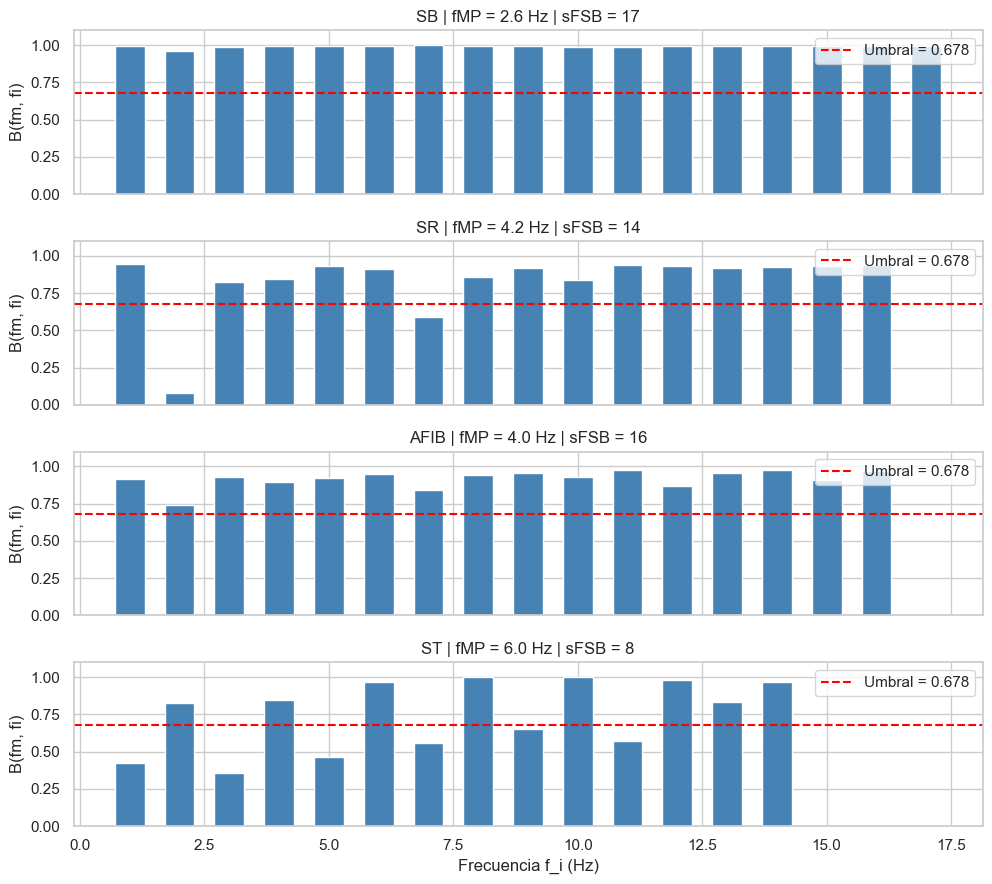

In [73]:
# PUNTO 5: Suma de frecuencias significativas para bicoherencia (sFSB)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

L = 500   # muestras por segmento, igual que en el punto 3: N = 10 segmentos, umbral = 0.678

def senal_procesada(filename):
    """Lee el registro (derivación II), quita la tendencia y comprime, como en el punto 4."""
    x = pd.read_csv(SIGNALS_DIR / f"{filename}.csv", header=None).iloc[:, LEAD_INDEX].values
    return comprimir(quitar_tendencia(x, GRADO_DETREND))

def sfsb_senal(x, fm, fs=FS, L=L, fmax=FMAX):
    """Número de frecuencias f_i con B(fm, f_i) > sqrt(9.2 / (2N)).
    Solo se cuentan los f_i con fm + f_i <= fmax (dominio del artículo).
    fm se aproxima a la frecuencia más cercana de la malla de la bicoherencia (1 Hz)."""
    f, B, N = bicoherencia(x, fs, L, fmax)
    i = np.argmin(np.abs(f - fm))
    validas = (f + f[i]) <= fmax
    return int(np.sum((B[i, :] > umbral_bicoherencia(N)) & validas))

# Comprobación: con L = 500 debe dar N = 10 y umbral 0.678
x0 = senal_procesada(df_sel["FileName"].iloc[0])
_, _, N0 = bicoherencia(x0, FS, L, FMAX)
print(f"N = {N0} segmentos | umbral = {umbral_bicoherencia(N0):.3f}")
assert N0 == 10, "N no es 10: revisa que L sea 500"

# Demostración: una señal de cada ritmo del subconjunto
fig, axes = plt.subplots(len(ritmos_sel), 1, figsize=(10, 9), sharex=True)
for ax, ritmo in zip(axes, ritmos_sel):
    fila = df_sel[df_sel["Rhythm"] == ritmo].iloc[0]
    x = senal_procesada(fila["FileName"])
    fm = fila["fMP"]
    f, B, N = bicoherencia(x, FS, L, FMAX)
    umbral = umbral_bicoherencia(N)
    i = np.argmin(np.abs(f - fm))
    validas = (f + f[i]) <= FMAX
    n_sig = sfsb_senal(x, fm)

    ax.bar(f[validas], B[i, validas], width=0.6, color="steelblue")
    ax.axhline(umbral, color="red", linestyle="--", label=f"Umbral = {umbral:.3f}")
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("B(fm, fi)")
    ax.set_title(f"{ritmo} | fMP = {fm:.1f} Hz | sFSB = {n_sig}")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Frecuencia f_i (Hz)")
plt.tight_layout()
plt.show()


La bicoherencia $B(f_1, f_2)$ mide qué tan acoplada está la fase de tres componentes de frecuencia $f_1$, $f_2$ y $f_1 + f_2$ (fórmula 4 del punto 3). El artículo [7] la usa tomando como referencia la **frecuencia de máxima potencia** $f_m$, calculada en el punto 4, y contando con cuántas otras frecuencias $f_i$ está acoplada de forma significativa. Para cada señal, el **sFSB** es el número de frecuencias $f_i$ tales que

$$B(f_m, f_i) > \sqrt{\frac{9.2}{2N}}$$

donde $N$ es el número de segmentos en que se divide la señal. El artículo define además otros dos conteos: con la frecuencia del pulso ($f_0$, $f_i$) y entre los demás pares ($f_i$, $f_j$). Se eligió el de $f_m$ porque es el que usa la fMP del punto 4 y porque el enunciado habla de "frecuencias" y no de pares. 

**Parámetros y método**

**Señal.** Derivación II, con la tendencia restada y la compresión aplicadas igual que en el punto 4, de modo que fMP y sFSB describan la misma señal.

**Segmentos y umbral.** Se usó $L = 500$ muestras (1 s), igual que en el punto 3, que da $N = 10$ segmentos sin solapamiento, una resolución en frecuencia de 1 Hz y un umbral $\sqrt{9.2/(2N)} = 0{,}678$. La constante 9,2 es la del artículo [7], y coincide con el valor crítico de una chi-cuadrado con 2 grados de libertad para $p \approx 0{,}01$; el artículo la presenta como nivel de significancia del 80 %.

**Frecuencias consideradas.** Se cuentan los $f_i$ entre 1 y 20 Hz con $f_m + f_i \le 20$ Hz, que es el dominio del artículo. Como la malla de la bicoherencia es de 1 Hz y la fMP tiene resolución de 0,1 Hz, $f_m$ se aproxima a la frecuencia más cercana de la malla. Por esta restricción el máximo posible del sFSB depende de $f_m$: con $f_m \approx 3$ Hz hay 17 frecuencias candidatas y con $f_m \approx 6$ Hz hay 14.

**Procedimiento.** La función `sfsb_senal(x, fm)` calcula la bicoherencia con las funciones del punto 3, toma la fila correspondiente a $f_m$, descarta los $f_i$ con $f_m + f_i > 20$ Hz y cuenta cuántos de los restantes superan el umbral.

**Ejemplo en una señal de cada ritmo**

La figura muestra $B(f_m, f_i)$ para una señal de cada ritmo, con el umbral en rojo. En SB la fMP fue 2,6 Hz y el sFSB 17 de 17 candidatas; en SR, 4,2 Hz y 14 de 16; en AFIB, 4,0 Hz y 16 de 16; y en ST, 6,0 Hz y 8 de 14. Al ser una señal por ritmo, el ejemplo ilustra el método pero no permite comparar los ritmos; esa comparación se hace en los puntos 7 y 8 con todo el subconjunto.


**Cómo interpretar el sFSB**

El complejo QRS es un pulso muy estrecho. Cuando un segmento contiene un único pulso, la bicoherencia sale cercana a 1 en casi todos los pares de frecuencias, porque la posición del pulso no afecta el producto de las tres componentes. Esto coincide con lo observado: en SB hay menos de un latido por segmento de 1 s y todas las barras superan el umbral. Con dos o más latidos por segmento, como en ST, los pulsos interfieren y la bicoherencia varía entre frecuencias. Por eso el sFSB no mide solo acoplamiento no lineal, sino que también depende de cuántos latidos caen en cada segmento, es decir, de la frecuencia cardíaca. Es una explicación coherente con los gráficos, pero no se verificó de forma independiente. Se tendrá en cuenta en la interpretación del punto 8.


---

**6. Crear una rutina que aplique sobre todos los archivos de la base de datos las rutinas 3 al 5 y almacene los resultados en un dataframe donde se pueda ver registro, tipo de patología, la frecuencia de máxima potencia (fMP) y la suma de frecuencias significativas en bicoherencia (sFSB).**

| Registro | Estado | fMP | sFSB |
|----------|--------|-----|------|
|          |        |     |      |

In [74]:
# PUNTO 6: Rutina masiva (puntos 3 a 5 sobre todos los registros)
import time
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm   # si falla: pip install tqdm

assert L == 500, "L debe ser 500 (igual que en el punto 3)"

def fmp_senal(x, fs=FS, fmin=FMIN, fmax=FMAX):
    """fMP de una señal ya preprocesada (mismo cálculo del punto 4)."""
    f = np.fft.rfftfreq(len(x), d=1/fs)
    P = np.abs(np.fft.rfft(x))**2 / len(x)
    zona = (f >= fmin) & (f <= fmax)
    return f[zona][np.argmax(P[zona])]

def procesar_registro(filename):
    """Aplica las rutinas de los puntos 3 a 5 a un registro y devuelve (fMP, sFSB)."""
    x = pd.read_csv(SIGNALS_DIR / f"{filename}.csv", header=None, usecols=[LEAD_INDEX]).iloc[:, 0].values
    if not np.all(np.isfinite(x)) or np.ptp(x) == 0:
        raise ValueError("señal con valores no válidos o constante")
    s = comprimir(quitar_tendencia(x, GRADO_DETREND))   # punto 3: sin tendencia y comprimida
    fm = fmp_senal(s)                                   # punto 4
    return fm, sfsb_senal(s, fm)                        # punto 5

BASE_PROCESO = df            # todos los registros; los puntos 7 y 8 se filtran con df_sel
N_PRUEBA = None       # prueba de tiempo con n registros; poner None para correr todo
RUTA_RESULTADOS = Path("resultados_fmp_sfsb.csv")
RECALCULAR = True      # True para ignorar el CSV guardado

if N_PRUEBA is None and RUTA_RESULTADOS.exists() and not RECALCULAR:
    resultados = pd.read_csv(RUTA_RESULTADOS)
    print(f"Resultados cargados desde {RUTA_RESULTADOS}")
else:
    base = BASE_PROCESO if N_PRUEBA is None else BASE_PROCESO.head(N_PRUEBA)
    filas, errores = [], []
    t0 = time.time()
    for k, (fn, ritmo) in enumerate(tqdm(zip(base["FileName"], base["Rhythm"]), total=len(base)), 1):
        try:
            fm, n_sig = procesar_registro(fn)
        except Exception as e:
            fm, n_sig = np.nan, np.nan
            errores.append((fn, str(e)))
        filas.append({"Registro": fn, "Estado": ritmo, "fMP": fm, "sFSB": n_sig})
        if N_PRUEBA is None and k % 1000 == 0:          # respaldo por si se interrumpe
            pd.DataFrame(filas).to_csv("resultados_parcial.csv", index=False)
    resultados = pd.DataFrame(filas)

    seg = time.time() - t0
    print(f"{seg/len(base):.3f} s por registro | {seg/60:.1f} min en {len(base)} registros")
    if N_PRUEBA is None:
        resultados.to_csv(RUTA_RESULTADOS, index=False)
        print(f"Guardado en {RUTA_RESULTADOS}")
    else:
        print(f"Estimado para {len(BASE_PROCESO)} registros: {seg/len(base)*len(BASE_PROCESO)/60:.1f} min")
    print(f"Con error: {len(errores)}")
    if errores:
        display(pd.DataFrame(errores, columns=["Registro", "Error"]).head())

display(resultados.head())
print(resultados.shape, "| faltantes:", resultados[["fMP", "sFSB"]].isna().sum().to_dict())

# # Comprobación: la fMP coincide con la calculada en el punto 4 (sin los registros con error)
chk = resultados.merge(df_sel[["FileName", "fMP"]], left_on="Registro", right_on="FileName", suffixes=("", "_p4"))
ok = chk["fMP"].notna()
print("fMP coincide con el punto 4:", np.allclose(chk.loc[ok, "fMP"], chk.loc[ok, "fMP_p4"]),
      f"({ok.sum()} registros comparados, {(~ok).sum()} con error)")
print("sFSB mínimo y máximo:", int(resultados["sFSB"].min()), int(resultados["sFSB"].max()))

  0%|          | 0/10646 [00:00<?, ?it/s]

100%|██████████| 10646/10646 [03:41<00:00, 48.07it/s]


0.021 s por registro | 3.7 min en 10646 registros
Guardado en resultados_fmp_sfsb.csv
Con error: 41


,Registro,Error
0,MUSE_20180113_124215_52000,N = 3 segmentos da un umbral >= 1; usa una ven...
1,MUSE_20181222_204118_08000,señal con valores no válidos o constante
2,MUSE_20181222_204121_42000,señal con valores no válidos o constante
3,MUSE_20181222_204122_52000,señal con valores no válidos o constante
4,MUSE_20181222_204123_64000,señal con valores no válidos o constante


,Registro,Estado,fMP,sFSB
0,MUSE_20180113_171327_27000,AFIB,9.0,10.0
1,MUSE_20180112_073319_29000,SB,2.6,17.0
2,MUSE_20180111_165520_97000,SA,1.1,18.0
3,MUSE_20180113_121940_44000,SB,0.9,19.0
4,MUSE_20180112_122850_57000,AF,5.4,7.0


(10646, 4) | faltantes: {'fMP': 41, 'sFSB': 41}
fMP coincide con el punto 4: True (6830 registros comparados, 1 con error)
sFSB mínimo y máximo: 0 19



**Rutina**

La función `procesar_registro(nombre_archivo)` aplica a un registro, en este orden, las rutinas de los puntos anteriores:

1. Lee la derivación II del archivo CSV y verifica que la señal sea válida (valores numéricos y no constante).
2. Le resta la tendencia polinómica de grado 5 y la comprime (fórmulas 1 y 2 del punto 3).
3. Calcula la frecuencia de máxima potencia $f_m$ (punto 4).
4. Cuenta las frecuencias $f_i$ con $B(f_m, f_i)$ significativa (punto 5), con $L = 500$, $N = 10$ y umbral 0,678.

La rutina se aplicó a los **10.646 registros** de la base de datos y no solo al subconjunto, como pide el enunciado. El subconjunto del punto 2.8 se usa después para el análisis estadístico (puntos 7 y 8). Cada registro se empareja con su diagnóstico por el nombre del archivo (`FileName` de `Diagnostics.xlsx`).

**DataFrame de resultados**

| Registro | Estado | fMP | sFSB |
|---|---|---|---|
| Nombre del archivo | Ritmo (`Rhythm`) | Frecuencia de máxima potencia (Hz) | Número de frecuencias significativas |

El resultado se guardó en `resultados_fmp_sfsb.csv` para no tener que recalcularlo. La rutina completa tardó 3,7 minutos (0,021 s por registro).

**Control de calidad**

**Registros sin resultado.** De los 10.646 registros, 41 (0,4 %) no se pudieron procesar y quedaron como valores faltantes (NaN), sin imputar. Se excluyeron en lugar de inventar un valor:

- **40 registros** del ritmo SVT tienen una señal constante o con valores no numéricos, por lo que no contienen ECG que analizar.

- **1 registro** del ritmo SB es más corto de lo normal (menos de 2.000 muestras): con segmentos de 500 muestras solo se obtienen 3 segmentos, y el umbral $\sqrt{9.2/(2N)}$ supera 1, así que la bicoherencia no es interpretable.

Solo ese último pertenece al subconjunto del punto 2.8, de modo que el análisis de los puntos 7 y 8 se hace con 6.830 de las 6.831 señales.

**Coherencia con el punto 4.** La fMP calculada por la rutina masiva coincide con la del punto 4 en los 6.830 registros del subconjunto que se pudieron procesar.

**Valores esperados.** El sFSB debe estar entre 0 y 19, que es el máximo de frecuencias candidatas cuando $f_m \approx 1$ Hz. Se verificó que ningún valor lo supera.

---

**7. Para las señales de análisis del punto 2 aplicar las rutinas del punto 3 al
5 y hacer un informe que permita evidenciar las diferencias entre las
señales las diferentes arritmias utilizando las herramientas de estadística
descriptiva**

100%|██████████| 6831/6831 [02:26<00:00, 46.55it/s]


6830 señales procesadas | 1 excluida(s) por error
Coincide con el punto 6: True

fMP


,n,media,desv,min,Q1,mediana,Q3,max,RIC
Estado,,,,,,,,,
SB,3297,2.75,1.84,0.4,1.00,2.8,3.7,16.3,2.70
SR,1374,3.79,1.83,0.7,2.60,3.6,4.6,15.5,2.00
AFIB,1162,4.32,2.87,0.3,2.52,3.6,5.0,18.2,2.48
ST,997,5.21,2.28,0.6,3.50,5.2,6.4,18.8,2.90



sFSB


,n,media,desv,min,Q1,mediana,Q3,max,RIC
Estado,,,,,,,,,
SB,3297,16.42,2.20,0,16.0,17.0,18.0,19,2.0
SR,1374,14.63,2.67,2,13.0,15.0,16.0,19,3.0
AFIB,1162,13.56,3.74,0,12.0,14.0,16.0,19,4.0
ST,997,11.99,2.85,0,10.0,12.0,14.0,18,4.0


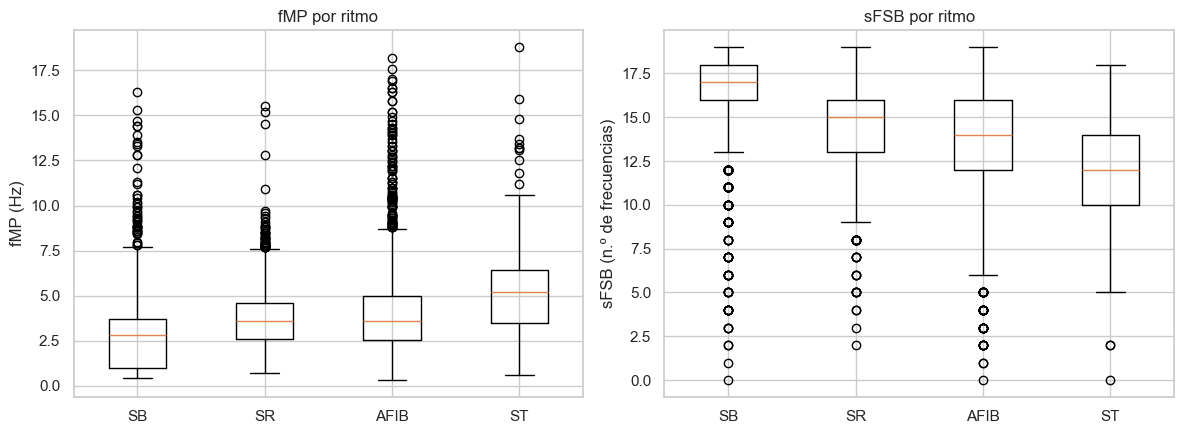

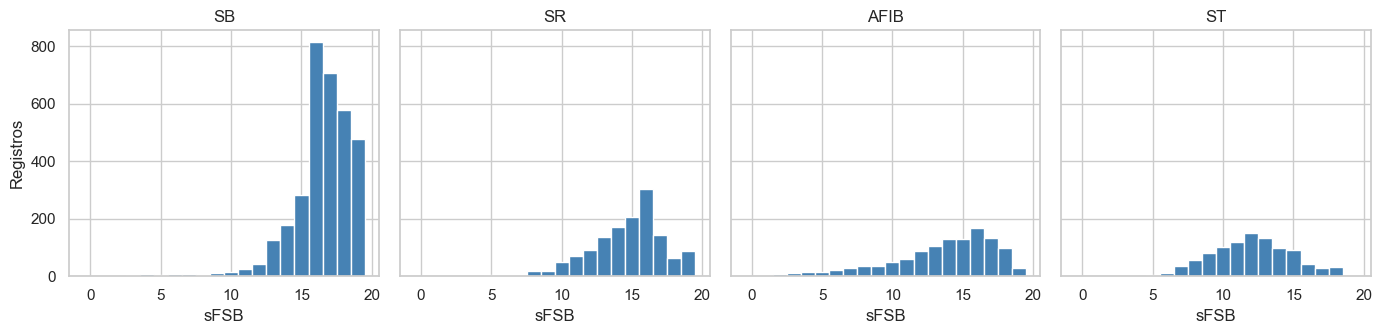

In [75]:
# PUNTO 7: Estadística descriptiva de fMP y sFSB por ritmo (subconjunto del punto 2)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

ORDEN = ["SB", "SR", "AFIB", "ST"]

# 1. Aplicar las rutinas de los puntos 3 a 5 a las señales del subconjunto
filas, errores = [], []
for fn, ritmo in tqdm(zip(df_sel["FileName"], df_sel["Rhythm"]), total=len(df_sel)):
    try:
        fm, n_sig = procesar_registro(fn)      # punto 3 (preproceso), 4 (fMP) y 5 (sFSB)
        filas.append({"Registro": fn, "Estado": ritmo, "fMP": fm, "sFSB": n_sig})
    except Exception as e:
        errores.append((fn, str(e)))

res_sub = pd.DataFrame(filas)
res_sub["sFSB"] = res_sub["sFSB"].astype(int)
print(f"{len(res_sub)} señales procesadas | {len(errores)} excluida(s) por error")

# Comprobación: coincide con la tabla masiva del punto 6
chk = res_sub.merge(resultados, on="Registro", suffixes=("", "_p6"))
print("Coincide con el punto 6:", np.allclose(chk["fMP"], chk["fMP_p6"]) and (chk["sFSB"] == chk["sFSB_p6"]).all())

# 2. Estadística descriptiva por ritmo
def tabla_descriptiva(variable):
    g = res_sub.groupby("Estado")[variable]
    t = g.agg(n="count", media="mean", desv="std", min="min",
              Q1=lambda s: s.quantile(0.25), mediana="median",
              Q3=lambda s: s.quantile(0.75), max="max")
    t["RIC"] = t["Q3"] - t["Q1"]          # rango intercuartílico
    return t.loc[ORDEN].round(2)

for v in ["fMP", "sFSB"]:
    print(f"\n{v}")
    display(tabla_descriptiva(v))

# 3. Boxplots de cada variable por ritmo
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, v, etiqueta in zip(axes, ["fMP", "sFSB"], ["fMP (Hz)", "sFSB (n.º de frecuencias)"]):
    datos = [res_sub.loc[res_sub["Estado"] == r, v] for r in ORDEN]
    ax.boxplot(datos)
    ax.set_xticklabels(ORDEN)
    ax.set_ylabel(etiqueta)
    ax.set_title(f"{v} por ritmo")
plt.tight_layout()
plt.show()

# 4. Distribución del sFSB por ritmo
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, r in zip(axes, ORDEN):
    ax.hist(res_sub.loc[res_sub["Estado"] == r, "sFSB"], bins=np.arange(-0.5, 20.5, 1), color="steelblue")
    ax.set_title(r)
    ax.set_xlabel("sFSB")
axes[0].set_ylabel("Registros")
plt.tight_layout()
plt.show()


**Señales analizadas**

Se analizaron las **6.830 señales** del subconjunto del punto 2.8 (SB 3.297, SR 1.374, AFIB 1.162 y ST 997), tomando de la tabla del punto 6 la fMP y el sFSB de cada una. Se excluyó el registro del subconjunto que no pudo procesarse (ver 6.3). Como las distribuciones son asimétricas y tienen valores extremos, además de la media y la desviación estándar se reporta la **mediana y el rango intercuartílico (RIC)**, que son menos sensibles a esos valores.

**Frecuencia de máxima potencia (fMP)**

| Ritmo | n | Media ± desv. (Hz) | Mediana [Q1 – Q3] (Hz) | RIC | Mín – Máx (Hz) |
|---|---|---|---|---|---|
| SB | 3.297 | 2,75 ± 1,84 | 2,8 [1,00 – 3,70] | 2,70 | 0,4 – 16,3 |
| SR | 1.374 | 3,79 ± 1,83 | 3,6 [2,60 – 4,60] | 2,00 | 0,7 – 15,5 |
| AFIB | 1.162 | 4,32 ± 2,87 | 3,6 [2,52 – 5,00] | 2,48 | 0,3 – 18,2 |
| ST | 997 | 5,21 ± 2,28 | 5,2 [3,50 – 6,40] | 2,90 | 0,6 – 18,8 |

**Qué se observa.**

- **Orden de las medianas.** La fMP aumenta en el orden SB (2,8 Hz), SR (3,6 Hz) y ST (5,2 Hz), el mismo orden de la frecuencia cardíaca, como se esperaba (sección 4.5). SB y ST se separan claramente: la mediana de ST es casi el doble.
- **SR y AFIB.** Tienen la misma mediana (3,6 Hz), por lo que en el centro de la distribución la fMP no los distingue. Se diferencian en la dispersión: la desviación de AFIB (2,87 Hz) es la mayor de los cuatro ritmos y la de SR (1,83 Hz) es de las menores.
- **Cola superior.** En todos los ritmos hay valores extremos por encima de 10 Hz, pero son más frecuentes en AFIB (70 de 1.162, el 6 %) que en ST (2,3 %), SB (0,6 %) o SR (0,4 %). Por eso la media de AFIB (4,32 Hz) queda por encima de su mediana (3,6 Hz).
- **SB.** El primer cuartil es 1,0 Hz, lo que sugiere que en una parte de estos registros el máximo cae en la frecuencia cardíaca misma (cercana a 1 Hz) y no en un armónico.

**Suma de frecuencias significativas (sFSB)**

| Ritmo | n | Media ± desv. | Mediana [Q1 – Q3] | RIC | Mín – Máx |
|---|---|---|---|---|---|
| SB | 3.297 | 16,42 ± 2,20 | 17 [16 – 18] | 2 | 0 – 19 |
| SR | 1.374 | 14,63 ± 2,67 | 15 [13 – 16] | 3 | 2 – 19 |
| AFIB | 1.162 | 13,56 ± 3,74 | 14 [12 – 16] | 4 | 0 – 19 |
| ST | 997 | 11,99 ± 2,85 | 12 [10 – 14] | 4 | 0 – 18 |

**Qué se observa.**

- **Orden de las medianas.** El sFSB disminuye en el orden SB (17), SR (15), AFIB (14) y ST (12). Es el orden inverso al de la fMP.
- **Forma de la distribución.** En los histogramas todos los ritmos presentan asimetría hacia valores bajos: la mayoría de los registros se concentra en valores altos y una minoría se extiende hacia abajo. En SB la distribución es la más concentrada (RIC = 2) y se acumula cerca del máximo posible; en ST es más simétrica y centrada en 12.
- **AFIB.** Tiene la mayor dispersión (desviación 3,74; RIC = 4) y la cola más larga hacia valores bajos, coherente con un ritmo irregular en el que el acoplamiento de fase entre componentes es menos constante.
- **Valores extremos.** Hay registros con sFSB muy bajo (hasta 0) en SB, AFIB y ST, visibles como puntos aislados en el diagrama de cajas.

**Resumen de las diferencias entre ritmos**

- Las dos variables ordenan los ritmos de forma consistente con la frecuencia cardíaca: SB es el más lento (fMP más baja y sFSB más alto) y ST el más rápido (fMP más alta y sFSB más bajo), con SR en una posición intermedia.
- AFIB se parece a SR en la mediana de la fMP, pero es el ritmo con mayor variabilidad en ambas variables.
- Hay un solapamiento importante entre ritmos en las dos variables: los rangos intercuartílicos de SR y AFIB se cruzan casi por completo, y las colas de todos los ritmos llegan a valores muy distintos de su mediana.

**Limitaciones de esta lectura.** La estadística descriptiva muestra las diferencias, pero no dice si son significativas; eso se evalúa en el punto 8. Además, tanto fMP como sFSB dependen de la frecuencia cardíaca (sección 4.5 y 5.4), y el sFSB tiene un máximo que depende de la fMP (sección 5.2), por lo que parte de las diferencias observadas puede reflejar la frecuencia cardíaca y no información espectral independiente.

---

**8.Indicar si hay o no diferencias estadísticas entre las características espectrales del punto 4 y 5 para las poblaciones de estudio**

In [76]:
# PUNTO 8: Diferencias estadísticas de fMP y sFSB entre ritmos
import numpy as np
import pandas as pd
from itertools import combinations
from scipy import stats

VARS = ["fMP", "sFSB"]
ALFA = 0.05

#1. Pruebas de normalidad por ritmo
filas = []
for v in VARS:
    for r in ORDEN:
        x = res_sub.loc[res_sub["Estado"] == r, v]
        est_dp, p_dp = stats.normaltest(x)      # D'Agostino-Pearson
        W, p_sw = stats.shapiro(x)              # Shapiro-Wilk
        filas.append({"Variable": v, "Ritmo": r, "n": len(x),
                      "Asimetría": round(stats.skew(x), 2),
                      "p D'Agostino": f"{p_dp:.1e}",
                      "W Shapiro": round(W, 3),
                      "p Shapiro": f"{p_sw:.1e}",
                      "¿Normal? (ambas)": "Sí" if (p_dp >= ALFA and p_sw >= ALFA) else "No"})
print("Pruebas de normalidad (H0: la distribución es normal)")
display(pd.DataFrame(filas))

#2. Prueba global: Kruskal-Wallis
N, k = len(res_sub), len(ORDEN)
filas = []
for v in VARS:
    grupos = [res_sub.loc[res_sub["Estado"] == r, v] for r in ORDEN]
    H, p = stats.kruskal(*grupos)
    eta2 = (H - k + 1) / (N - k)            # tamaño del efecto (eta² basado en H)
    filas.append({"Variable": v, "H": round(H, 1), "p-valor": f"{p:.1e}", "eta²": round(eta2, 3)})
print("\nKruskal-Wallis entre los 4 ritmos (H0: las distribuciones son iguales)")
display(pd.DataFrame(filas))

#3. Comparaciones por pares: Mann-Whitney + Bonferroni + delta de Cliff
pares = list(combinations(ORDEN, 2))
def magnitud(d):
    d = abs(d)
    return "insignificante" if d < 0.147 else "pequeño" if d < 0.33 else "mediano" if d < 0.474 else "grande"

filas = []
for v in VARS:
    for a, b in pares:
        x = res_sub.loc[res_sub["Estado"] == a, v]
        y = res_sub.loc[res_sub["Estado"] == b, v]
        U, p = stats.mannwhitneyu(x, y, alternative="two-sided")
        delta = 2 * U / (len(x) * len(y)) - 1          # delta de Cliff (a vs b)
        p_adj = min(p * len(pares), 1.0)                # Bonferroni
        filas.append({"Variable": v, "Par": f"{a} vs {b}",
                      "Mediana A": x.median(), "Mediana B": y.median(),
                      "p ajustado": f"{p_adj:.1e}", "Cliff δ": round(delta, 2),
                      "Magnitud": magnitud(delta),
                      "¿Significativa?": "Sí" if p_adj < ALFA else "No"})
print("\nComparaciones por pares (Bonferroni, 6 pares)")
display(pd.DataFrame(filas))

Pruebas de normalidad (H0: la distribución es normal)


,Variable,Ritmo,n,Asimetría,p D'Agostino,W Shapiro,p Shapiro,¿Normal? (ambas)
0,fMP,SB,3297,1.67,6.5e-261,0.848,1.0e-48,No
1,fMP,SR,1374,1.16,1.6e-70,0.926,1.5e-25,No
2,fMP,AFIB,1162,1.89,1.0e-96,0.820,3.8e-34,No
3,fMP,ST,997,0.77,2.1e-28,0.951,9.5e-18,No
4,sFSB,SB,3297,-2.13,0.0e+00,0.825,4.3e-51,No
5,sFSB,SR,1374,-0.81,9.1e-34,0.946,6.4e-22,No
6,sFSB,AFIB,1162,-0.98,1.0e-32,0.921,3.4e-24,No
7,sFSB,ST,997,-0.12,2.8e-01,0.984,3.5e-09,No



Kruskal-Wallis entre los 4 ritmos (H0: las distribuciones son iguales)


,Variable,H,p-valor,eta²
0,fMP,1239.8,1.7e-268,0.181
1,sFSB,1968.4,0.0e+00,0.288



Comparaciones por pares (Bonferroni, 6 pares)


,Variable,Par,Mediana A,Mediana B,p ajustado,Cliff δ,Magnitud,¿Significativa?
0,fMP,SB vs SR,2.8,3.6,4.8e-96,-0.39,mediano,Sí
1,fMP,SB vs AFIB,2.8,3.6,1.6e-84,-0.38,mediano,Sí
2,fMP,SB vs ST,2.8,5.2,3.0e-193,-0.62,grande,Sí
3,fMP,SR vs AFIB,3.6,3.6,4.7e-01,-0.04,insignificante,No
4,fMP,SR vs ST,3.6,5.2,2.1e-61,-0.40,mediano,Sí
5,fMP,AFIB vs ST,3.6,5.2,1.2e-36,-0.32,pequeño,Sí
6,sFSB,SB vs SR,17.0,15.0,1.8e-126,0.44,mediano,Sí
7,sFSB,SB vs AFIB,17.0,14.0,1.2e-147,0.51,grande,Sí
8,sFSB,SB vs ST,17.0,12.0,0.0e+00,0.79,grande,Sí
9,sFSB,SR vs AFIB,15.0,14.0,5.9e-08,0.13,insignificante,Sí



Las poblaciones comparadas son los cuatro ritmos del subconjunto del punto 2.8: SB (n = 3.297), SR (1.374), AFIB (1.162) y ST (997). La fMP y el sFSB se compararon por separado, con un nivel de significancia de 0,05. El análisis sigue tres pasos: verificar si los datos son normales para elegir el tipo de prueba, comparar los cuatro ritmos a la vez y, si hay diferencias, identificar entre cuáles ritmos están.

**Elección del tipo de prueba: normalidad**

**Qué se hizo.** Se evaluó la normalidad de cada variable en cada ritmo (H₀: la distribución es normal; si p < 0,05 se rechaza). La decisión de usar pruebas paramétricas (que suponen datos normales) o no paramétricas depende de este resultado.

**Por qué dos pruebas.** Se aplicaron dos pruebas de normalidad complementarias. Shapiro-Wilk es la más usada y la más potente para detectar desviaciones de la normalidad, y es adecuada aquí porque ningún ritmo supera las 5.000 señales (el máximo es SB con 3.297). Su estadístico W vale 1 para una distribución perfectamente normal y disminuye a medida que los datos se alejan de ella. La prueba de D'Agostino-Pearson contrasta la asimetría y la curtosis con las de una normal, lo que permite ver en qué sentido se desvían los datos. Con miles de señales ambas rechazan la normalidad ante desviaciones pequeñas, por lo que sus p-valores no se interpretan solos, sino junto con la asimetría y con los histogramas y diagramas de cajas del punto 7.

| Variable | Ritmo | Asimetría | p D'Agostino | W Shapiro | p Shapiro | ¿Normal? |
|---|---|---|---|---|---|---|
| fMP | SB | 1,67 | 6,5·10⁻²⁶¹ | 0,848 | 1,0·10⁻⁴⁸ | No |
| fMP | SR | 1,16 | 1,6·10⁻⁷⁰ | 0,926 | 1,5·10⁻²⁵ | No |
| fMP | AFIB | 1,89 | 1,0·10⁻⁹⁶ | 0,820 | 3,8·10⁻³⁴ | No |
| fMP | ST | 0,77 | 2,1·10⁻²⁸ | 0,951 | 9,5·10⁻¹⁸ | No |
| sFSB | SB | −2,13 | < 10⁻³⁰⁰ | 0,825 | 4,3·10⁻⁵¹ | No |
| sFSB | SR | −0,81 | 9,1·10⁻³⁴ | 0,946 | 6,4·10⁻²² | No |
| sFSB | AFIB | −0,98 | 1,0·10⁻³² | 0,921 | 3,4·10⁻²⁴ | No |
| sFSB | ST | −0,12 | 0,28 | 0,984 | 3,5·10⁻⁹ | No |

**Qué se observa.** Shapiro-Wilk rechaza la normalidad en los ocho grupos, y D'Agostino-Pearson en siete. La fMP tiene asimetría positiva (cola larga hacia valores altos) y el sFSB, negativa (cola hacia valores bajos), lo que coincide con los histogramas y diagramas de cajas del punto 7. Las desviaciones más fuertes (W entre 0,82 y 0,85) están en la fMP de SB y AFIB y en el sFSB de SB. El único caso en que las pruebas discrepan es el sFSB de ST: su distribución es casi simétrica (asimetría −0,12 y W = 0,984, muy cercano a 1) y D'Agostino-Pearson no la rechaza (p = 0,28), pero Shapiro-Wilk sí, probablemente porque el sFSB es una variable discreta con muchos valores repetidos. Se considera una desviación leve, y en todo caso no cambia la decisión de abajo.

**Decisión: pruebas no paramétricas.** Se usaron en todas las comparaciones por tres razones: (1) las distribuciones son asimétricas y con valores extremos; (2) las desviaciones estándar difieren bastante entre ritmos (en la fMP de 1,83 a 2,87 Hz y en el sFSB de 2,20 a 3,74), y el ANOVA exige varianzas parecidas; y (3) el sFSB es una variable discreta y acotada (de 0 a 19). Con muestras tan grandes el ANOVA tolera cierta falta de normalidad, pero aquí se suman la asimetría, la heterogeneidad de varianzas y la naturaleza discreta del sFSB, por lo que las pruebas basadas en rangos, que no suponen una forma de distribución concreta y son poco sensibles a los valores extremos, son la opción más defendible.

**Comparación global entre los cuatro ritmos**

**Qué se hizo.** Se aplicó la prueba de Kruskal-Wallis, que es la alternativa no paramétrica al ANOVA: ordena todas las señales de menor a mayor y compara si los rangos promedio de los cuatro ritmos son iguales (H₀: los cuatro ritmos tienen la misma distribución). Como medida del tamaño del efecto se calculó el eta² basado en H, cuyas referencias convencionales son 0,01 (pequeño), 0,06 (mediano) y 0,14 (grande).

**Por qué primero una prueba global.** Comparar los ritmos de dos en dos desde el inicio implicaría seis pruebas por variable, y cada una aumenta la probabilidad de encontrar una diferencia por azar. La prueba global responde primero si hay alguna diferencia entre los cuatro ritmos, y solo si la hay tiene sentido buscar dónde está.

**Por qué reportar el tamaño del efecto.** El p-valor depende del número de datos: con ~6.800 señales una diferencia diminuta ya sale "significativa". El tamaño del efecto dice qué tan grande es la diferencia, independientemente del número de señales.

| Variable | H | p-valor | eta² |
|---|---|---|---|
| fMP | 1.239,8 | 1,7·10⁻²⁶⁸ | 0,181 |
| sFSB | 1.968,4 | < 10⁻³⁰⁰ | 0,288 |

**Qué se observa.** En ambas variables se rechaza H₀: **hay diferencias estadísticas entre los ritmos**, y el tamaño del efecto es grande (eta² > 0,14). El sFSB separa más los ritmos que la fMP (0,288 frente a 0,181), es decir, una proporción mayor de su variabilidad se explica por el ritmo.

**Comparaciones por pares**

**Qué se hizo.** Se aplicó la prueba de Mann-Whitney a los seis pares posibles de ritmos. Es la alternativa no paramétrica a la prueba t de dos muestras, y compara si los valores de un ritmo tienden a ser mayores que los del otro. Se usó una corrección de Bonferroni por variable.

**Por qué la corrección de Bonferroni.** Al hacer seis pruebas con un nivel de 0,05, la probabilidad de obtener al menos un falso positivo ronda el 26 %. Bonferroni lo evita multiplicando cada p-valor por el número de comparaciones (6); es una corrección conservadora, y que aun así queden valores muy pequeños indica que las diferencias son sólidas.

**Por qué el delta de Cliff.** Es el tamaño del efecto de Mann-Whitney: va de −1 a 1 y mide la diferencia entre la probabilidad de que un valor del primer ritmo sea mayor que uno del segundo y la probabilidad contraria. Un δ de 0 indica distribuciones superpuestas y uno cercano a ±1, casi separadas. Se interpretó con |δ| < 0,147 insignificante, hasta 0,33 pequeño, hasta 0,474 mediano y por encima grande. El signo indica cuál ritmo tiene valores mayores (negativo: el primero del par tiene valores menores).

| Variable | Par | Medianas | p ajustado | δ de Cliff | Magnitud | ¿Diferencia? |
|---|---|---|---|---|---|---|
| fMP | SB vs SR | 2,8 / 3,6 | 4,8·10⁻⁹⁶ | −0,39 | mediano | Sí |
| fMP | SB vs AFIB | 2,8 / 3,6 | 1,6·10⁻⁸⁴ | −0,38 | mediano | Sí |
| fMP | SB vs ST | 2,8 / 5,2 | 3,0·10⁻¹⁹³ | −0,62 | grande | Sí |
| fMP | SR vs AFIB | 3,6 / 3,6 | 0,47 | −0,04 | insignificante | **No** |
| fMP | SR vs ST | 3,6 / 5,2 | 2,1·10⁻⁶¹ | −0,40 | mediano | Sí |
| fMP | AFIB vs ST | 3,6 / 5,2 | 1,2·10⁻³⁶ | −0,32 | pequeño | Sí |
| sFSB | SB vs SR | 17 / 15 | 1,8·10⁻¹²⁶ | 0,44 | mediano | Sí |
| sFSB | SB vs AFIB | 17 / 14 | 1,2·10⁻¹⁴⁷ | 0,51 | grande | Sí |
| sFSB | SB vs ST | 17 / 12 | < 10⁻³⁰⁰ | 0,79 | grande | Sí |
| sFSB | SR vs AFIB | 15 / 14 | 5,9·10⁻⁸ | 0,13 | insignificante | Sí, pero efecto insignificante |
| sFSB | SR vs ST | 15 / 12 | 1,8·10⁻¹⁰² | 0,52 | grande | Sí |
| sFSB | AFIB vs ST | 14 / 12 | 6,2·10⁻³⁹ | 0,33 | pequeño | Sí |

**Qué se observa.**

- **Mayor separación.** SB y ST son los ritmos más distintos en las dos variables (δ = −0,62 en fMP y 0,79 en sFSB), con un orden claro: de SB a ST la fMP sube y el sFSB baja. Los pares con SB y ST tienen efecto mediano o grande.
- **fMP.** Distingue todos los pares salvo SR y AFIB, que comparten mediana (3,6 Hz) y no difieren (p = 0,47; δ = −0,04).
- **sFSB.** SR y AFIB sí difieren en sentido estadístico (p ajustado = 5,9·10⁻⁸), pero con efecto insignificante (δ = 0,13). Es el caso típico en que el p-valor es pequeño porque hay muchas señales, no porque la diferencia sea relevante.
- **Los p-valores extremadamente pequeños** (por ejemplo 10⁻²⁶⁸) indican que los datos son totalmente incompatibles con H₀, pero no miden qué tan grande es la diferencia; para eso se usan eta² y δ.

**Conclusión del punto 8.**

**Sí hay diferencias estadísticas entre los ritmos, tanto en la fMP como en el sFSB**, con un tamaño del efecto grande en ambos casos (eta² de 0,181 y 0,288). Las diferencias no se deben solo al gran número de señales, sino que representan una parte importante de la variabilidad de cada variable.

**Qué diferencias se encontraron.**

- **Orden de los ritmos.** Las dos variables ordenan los ritmos de forma coherente con la frecuencia cardíaca: SB tiene la fMP más baja (mediana de 2,8 Hz) y el sFSB más alto (17), ST tiene lo contrario (5,2 Hz y 12), y SR queda en una posición intermedia. SB y ST son los ritmos más distintos (δ = −0,62 en fMP y 0,79 en sFSB).
- **fMP.** Distingue todos los pares de ritmos salvo SR y AFIB, que comparten mediana (3,6 Hz) y no difieren (p = 0,47).
- **sFSB.** SR y AFIB difieren en sentido estadístico (p ajustado = 5,9·10⁻⁸), pero con un efecto insignificante (δ = 0,13), de modo que la diferencia se debe sobre todo al tamaño de la muestra.
- **AFIB.** Con estas dos características, la fibrilación auricular y el ritmo sinusal normal no se separan de forma útil. Además, las pruebas usadas comparan la posición de las distribuciones y no su dispersión, y AFIB se caracterizó en el punto 7 por una dispersión mucho mayor; esa diferencia no queda recogida aquí.

**Qué no se puede concluir.**

- **Una diferencia estadística no es una utilidad diagnóstica.** Que las distribuciones de dos ritmos sean distintas no significa que la fMP o el sFSB permitan clasificar una señal individual: las distribuciones se solapan bastante, como se ve en los diagramas de cajas del punto 7.
- **No se puede atribuir la diferencia a un acoplamiento de fase distinto.** La fMP es, en los ritmos regulares, un armónico de la frecuencia cardíaca (sección 4.5), y el sFSB depende de cuántos latidos caen en cada segmento (sección 5.4). Por eso parte de las diferencias entre ritmos refleja la frecuencia cardíaca y no una característica espectral independiente.

**Limitaciones.** No se ajustó por edad ni sexo, que pueden estar relacionados con el ritmo. El sFSB tiene un máximo que depende de la fMP (sección 5.2), lo que afecta sobre todo a los ritmos con fMP alta. Por último, con muestras de miles de señales los p-valores son extremadamente pequeños incluso para diferencias que carecen de relevancia práctica, por lo que las conclusiones se basan en el tamaño del efecto y no solo en la significancia.

**En resumen:** la fMP y el sFSB difieren de forma significativa y con efecto grande entre los ritmos, ordenándolos según la frecuencia cardíaca, pero no permiten distinguir la fibrilación auricular del ritmo sinusal normal, y parte de las diferencias puede explicarse por la frecuencia cardíaca.

---

**9. Informe con todos los puntos anteriores, incluyendo análisis de resultados y conclusiones**

Este informe resume el trabajo de los puntos 1 a 8, analiza los resultados, señala las limitaciones y presenta las conclusiones.

**9.1 Análisis de resultados**

**Base de datos y subconjunto (punto 2).** La base contiene 10.646 registros de ECG de 12 derivaciones (10 s a 500 Hz), uno por paciente, con 11 ritmos distintos. La bradicardia sinusal (SB) es el más frecuente (36,5 %), seguida del ritmo sinusal (SR, 17,2 %), la fibrilación auricular (AFIB, 16,7 %) y la taquicardia sinusal (ST, 14,7 %), que juntos suman el 85 % de la base. Si se excluye SR, que es el ritmo normal, las arritmias más prevalentes son SB (44,1 %), AFIB (20,2 %) y ST (17,8 %). El 55,9 % de los pacientes son hombres: SB es más frecuente en hombres (63,8 %) y SR y SVT lo son en mujeres (56,1 % y 52,5 % de mujeres). La edad se asocia con el ritmo: AFIB es el ritmo de pacientes de mayor edad (mediana de 75 años) y su proporción pasa de 0 % en menores de 18 años a 45 % en mayores de 80, mientras que la irregularidad sinusal (SA) predomina en jóvenes (mediana de 29 años; 45,7 % de los menores de 18).

Para los análisis siguientes se seleccionaron los cuatro ritmos con más registros (SB, SR, AFIB y ST) en pacientes de 40 a 79 años, lo que da un subconjunto de 6.831 registros (64,2 % de la base): SB 3.298, SR 1.374, AFIB 1.162 y ST 997. El rango de edad evita los casi inexistentes casos de AFIB antes de los 40 años (8 registros), a costa de dejar fuera 610 registros de AFIB en mayores de 79. Aun así, persiste una diferencia de edad entre ritmos (mediana de 69 años en AFIB frente a 58 en SR, 60 en SB y 61 en ST).

**Coincidencia con la literatura (punto 2.6).** Las tendencias de la base coinciden con la literatura: la prevalencia de la AFIB aumenta con la edad [4], la AVNRT afecta con más frecuencia a mujeres [5] (12 de los 16 registros de la base) y la arritmia sinusal es propia de personas jóvenes [6]. Las magnitudes, en cambio, difieren: el 45 % de los mayores de 80 años de la base tiene AFIB, frente al 10-17 % de la población general [4]. Esto se explica porque la base proviene de pacientes de un hospital y no de población general, por lo que sirve para comparar tendencias y no para estimar prevalencias.

**Fórmulas y características espectrales (puntos 3 a 6).** Las cuatro fórmulas del artículo [7] se programaron y se validaron con una señal sintética: la bicoherencia dio 1,0 con la fase acoplada y 0,39 sin acoplar. Como los registros son más cortos que los del artículo, se adaptaron dos parámetros: segmentos de 500 muestras (N = 10 segmentos sin solapamiento, resolución de 1 Hz y umbral de significancia de 0,678) y un polinomio de grado 5 para quitar la tendencia. La fMP se calculó en la derivación II entre 0,3 y 20 Hz, y el sFSB se definió como el número de frecuencias $f_i$ con bicoherencia significativa respecto a la fMP (de 0 a 19, según la fMP). La rutina masiva procesó los 10.646 registros en 3,7 minutos; 41 (0,4 %) no se pudieron calcular (40 señales constantes o inválidas del ritmo SVT y un registro de SB demasiado corto) y se excluyeron.

**Diferencias entre ritmos (puntos 7 y 8).** En las 6.830 señales analizables del subconjunto, la mediana de la fMP aumenta de SB (2,8 Hz) a SR (3,6 Hz) y ST (5,2 Hz), y la del sFSB disminuye de SB (17) a SR (15) y ST (12). AFIB tiene la misma mediana de fMP que SR (3,6 Hz), pero la mayor dispersión en ambas variables, y en el 6 % de sus registros la fMP supera los 10 Hz, frente a menos del 3 % en los demás ritmos. Las distribuciones no son normales, por lo que se usaron pruebas no paramétricas: hay diferencias significativas entre los ritmos en ambas variables, con efecto grande (eta² de 0,181 en la fMP y 0,288 en el sFSB). SB y ST son los ritmos más distintos (δ de Cliff de −0,62 en la fMP y 0,79 en el sFSB). SR y AFIB no difieren en la fMP (p = 0,47) y en el sFSB la diferencia es estadísticamente significativa pero de magnitud insignificante (δ = 0,13).

**Relación con los artículos.** En el artículo [7], en los ECG normales la frecuencia de máxima potencia coincide con la del pulso (cerca de 1 Hz). En las señales de SR de esta base, en cambio, la mediana de la fMP es de 3,6 Hz, que corresponde a un armónico de la frecuencia cardíaca (mediana de 74 latidos por minuto, es decir, 1,2 Hz). No se investigó la causa de esta diferencia: puede deberse al uso de la derivación II, a la menor duración de las señales o al preprocesamiento. Por otro lado, los artículos [2] y [3] clasifican las arritmias con muchas más características (histogramas de picos y valles, o redes convolucionales). Que aquí dos características espectrales no separen la AFIB del ritmo sinusal es coherente con la necesidad de usar rasgos más ricos para esa tarea.

**9.2 Limitaciones**

- **La frecuencia cardíaca actúa como variable de confusión.** La fMP es, en los ritmos regulares, un armónico de la frecuencia cardíaca (sección 4.5), y el sFSB depende de cuántos latidos caben en cada segmento de 1 s (sección 5.4). Por eso parte de las diferencias entre ritmos refleja la frecuencia cardíaca y no una característica espectral independiente.
- **Señales cortas y un solo canal.** Los registros duran 10 s (el artículo usa señales de 60 s), se usó solo la derivación II y, con N = 10 segmentos, la estimación de la bicoherencia es ruidosa y el umbral resulta alto (0,678).
- **Máximo del sFSB.** Solo se cuentan las frecuencias $f_i$ con $f_m + f_i \le 20$ Hz, por lo que el máximo posible depende de la fMP y desfavorece a los ritmos con fMP alta (sección 5.2).
- **Interpretación de la bicoherencia.** El complejo QRS es un pulso estrecho que puede producir bicoherencia cercana a 1 sin un acoplamiento no lineal real. Esta explicación es coherente con los resultados, pero no se verificó de forma independiente.
- **Valores extremos de la fMP.** El 1,7 % de las señales del subconjunto tuvo una fMP superior a 10 Hz (117 señales), y 70 de ellas son AFIB, lo que sugiere que en ese ritmo el máximo espectral puede no corresponder a un armónico de la frecuencia cardíaca.
- **Selección de los datos.** El subconjunto incluye solo cuatro ritmos y pacientes de 40 a 79 años, por lo que las conclusiones se limitan a esa población. Los datos provienen de un hospital y las proporciones de ritmos no representan a la población general.
- **Sin ajuste por edad ni sexo.** Los ritmos difieren en edad y en proporción de hombres (por ejemplo, 63,6 % en SB y 43,6 % en SR dentro del subconjunto), y no se controló su efecto.
- **Alcance de las pruebas estadísticas.** Las pruebas usadas comparan la posición de las distribuciones y no su dispersión, y no se evaluó la capacidad de clasificar señales individuales ni se validó con datos externos.
- **Decisiones propias.** El grado 5 del polinomio, la longitud de 500 muestras y la definición del sFSB respecto a la fMP son elecciones de este trabajo; el artículo trabaja con señales más largas y define otros conteos, de modo que alternativas razonables podrían dar valores distintos.

**9.3 Conclusiones**

1. **Las rutinas funcionan.** Las fórmulas del artículo se programaron y validaron, y la fMP y el sFSB se calcularon de forma automática para 10.605 de los 10.646 registros de la base.
2. **Hay diferencias entre los ritmos.** La fMP y el sFSB difieren de forma estadísticamente significativa y con efecto grande entre SB, SR, AFIB y ST. Ordenan los ritmos según la frecuencia cardíaca: SB tiene la fMP más baja y el sFSB más alto, y ST lo contrario.
3. **No separan la fibrilación auricular del ritmo sinusal.** AFIB y SR no difieren en la fMP, y en el sFSB la diferencia es insignificante en magnitud, aunque AFIB es el ritmo con mayor variabilidad en ambas variables. Esto limita el uso de estas dos características para detectar fibrilación auricular.
4. **Las diferencias reflejan en parte la frecuencia cardíaca.** No se puede atribuir el resultado únicamente a un acoplamiento de fase distinto entre ritmos.
5. **Para un uso diagnóstico habría que ir más lejos.** Serían necesarias señales más largas, controlar por frecuencia cardíaca, edad y sexo, y evaluar la capacidad de clasificar señales individuales con validación externa.

---

**Referencias**


[1] M. Gadaleta *et al.*, "Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias," *npj Digit. Med.*, vol. 6, no. 1, pp. 1–9, Dic. 2023, doi: 10.1038/s41746-023-00966-w.

[2] J. Zheng *et al.*, "Optimal multi-stage arrhythmia classification approach," *Sci. Rep.*, vol. 10, Art. no. 2898, Feb. 2020, doi: 10.1038/s41598-020-59821-7.

[3] L.-R. Liu *et al.*, "An arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection," *Heliyon*, vol. 10, no. 5, Art. no. e27200, 2024, doi: 10.1016/j.heliyon.2024.e27200.

[4] M. Zoni-Berisso, F. Lercari, T. Carazza y S. Domenicucci, "Epidemiology of atrial fibrillation: European perspective," *Clin. Epidemiol.*, vol. 6, pp. 213–220, 2014, doi: 10.2147/CLEP.S47385.

[5] R. A. Colucci, M. J. Silver y J. Shubrook, "Common types of supraventricular tachycardia: Diagnosis and management," *Am. Fam. Physician*, vol. 82, no. 8, pp. 942–952, Oct. 2010.

[6] M. P. Soos y D. McComb, "Sinus arrhythmia," en *StatPearls*. Treasure Island, FL, EE. UU.: StatPearls Publishing. [En línea]. Disponible en: https://www.ncbi.nlm.nih.gov/books/NBK537011/

[7] Y. Kotriwar, S. Kachhara, K. P. Harikrishnan y G. Ambika, "Higher order spectral analysis of ECG signals," arXiv:1809.08451, Sep. 2018. [En línea]. Disponible en: https://arxiv.org/pdf/1809.08451

[8] A. Lanatà, G. Valenza, C. Mancuso y E. P. Scilingo, "Robust multiple cardiac arrhythmia detection through bispectrum analysis," *Expert Syst. Appl.*, vol. 38, pp. 6798–6804, 2011, doi: 10.1016/j.eswa.2010.12.066.